In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage
from matplotlib.patches import Patch
from statannot import add_stat_annotation
from statannotations.Annotator import Annotator

import warnings
warnings.filterwarnings('ignore')


In [2]:
import statannotations
print("Statannotations version:", statannotations.__version__)

print("Seaborn version:", sns.__version__)

Statannotations version: 0.5.0
Seaborn version: 0.11.2


Give some basic Statistics

In [3]:
omics_with_demo_df = pd.read_csv('../data/merged_data/omics_aibl_demo.csv')
omics_with_demo_df = omics_with_demo_df.drop(['Gender'], axis=1)


In [19]:
omics_with_demo_df

,Acetone cyanohydrin,Acetone cyanohydrin.1,Diacetyl,2-Butyne-1_4-diol,2-Butyne-1_4-diol.1,2-Aminoacrylic acid,Malonic semialdehyde,Pyruvic acid,Butyric acid,Butyric acid.1,...,Age,Demographic.Sex,Demographic.Primary Occupation,Demographic.Retirement Status,Demographic.Current Marital Status,Demographic.Country of Birth,Demographic.Handedness,Vital Signs.Body Mass Index,Demographic.GDS,APOE4
0,-0.461142,-0.172676,0.010073,-0.099465,0.083470,0.652043,-0.210717,-0.162703,0.246997,-0.177819,...,69.0,Female,Other,Yes,Cohabiting,United Kingdom,Right,21.72,0.0,1.0
1,-0.270671,-0.276940,-0.261819,-0.032098,-0.098075,0.276904,-0.481847,-0.113594,0.390746,-0.217511,...,67.0,Female,Domestic Duties,Yes,Married,Australia,Right,NaN,1.0,NaN
2,0.256128,-0.239005,0.048329,0.137639,-0.086301,-0.638650,0.286983,0.075876,0.231817,0.251518,...,67.0,Female,Other,No,Married,Australia,Right,NaN,0.0,1.0
3,0.093526,0.448415,0.000368,-0.115477,-0.288924,-0.747549,-0.010582,0.428010,-0.424175,0.530050,...,69.0,Female,Clerical,Yes,Married,Australia,Right,NaN,0.0,1.0
4,-0.019898,-0.200684,0.663822,-0.468762,-0.193421,0.084386,-0.097456,-0.389847,0.891462,0.318160,...,70.0,Female,Teaching/Nursing,Yes,Married,Australia,Right,NaN,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,0.523049,0.027965,0.121575,-0.068759,-0.322383,0.444830,0.064232,0.278173,-0.318918,-0.273604,...,75.0,Male,Other,Yes,Married,Australia,Right,22.12,1.0,0.0
86,-0.197090,0.022827,-0.018414,0.057698,-0.227599,-0.732066,0.837810,0.425034,0.111957,0.172558,...,68.0,Male,Clerical,Yes,Married,Australia,Right,25.28,1.0,1.0
87,-0.510271,-0.239946,0.294435,-0.374088,-0.227367,-0.270230,0.190954,0.160205,0.180459,-0.144032,...,74.0,Male,Other,Yes,Married,Australia,Ambidextrous,26.10,0.0,1.0
88,-0.241158,-0.238286,0.144317,-0.210737,-0.123480,-1.056651,0.026226,0.228530,0.230646,-0.047158,...,73.0,Male,Other,Yes,Married,Australia,Right,28.63,1.0,1.0


In [4]:
basic_statistics_ft = ['Demographic.Years of Education Exact', 'Age', 'Demographic.Sex', 'Demographic.ApoE genotype', 'label','AIBL.ID','Collection']
basic_statis_info_df_APOE = omics_with_demo_df[basic_statistics_ft]
basic_statis_info_df_APOE

,Demographic.Years of Education Exact,Age,Demographic.Sex,Demographic.ApoE genotype,label,AIBL.ID,Collection
0,15.0,69.0,Female,E4/E2,H,837,7
1,NaN,67.0,Female,NaN,H,2276,1
2,10.0,67.0,Female,E4/E3,H,2274,1
3,10.0,69.0,Female,E4/E3,H,2321,1
4,NaN,70.0,Female,E3/E3,H,2326,1
...,...,...,...,...,...,...,...
85,20.0,75.0,Male,E3/E3,N,859,8
86,NaN,68.0,Male,E4/E3,N,2332,2
87,11.0,74.0,Male,E4/E3,N,1514,5
88,15.0,73.0,Male,E4/E3,N,2077,3


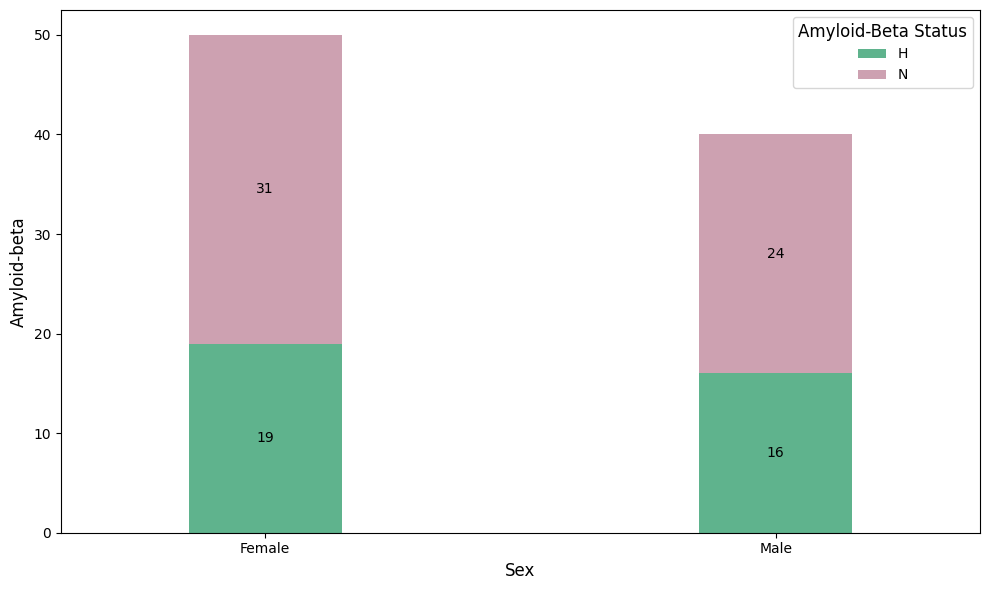

In [5]:
pivot_df_sex = basic_statis_info_df_APOE.groupby(['Demographic.Sex', 'label']).size().unstack(fill_value=0)
colors = ['#5fb38d', '#cda1b1']  # Light red for 'High', light blue for 'Normal'
ax = pivot_df_sex.plot(kind='bar', stacked=True, figsize=(10, 6), color=colors, width=0.3)
plt.xlabel('Sex', fontsize=12)
plt.ylabel('Amyloid-beta', fontsize=12)
plt.legend(title='Amyloid-Beta Status', title_fontsize='12', fontsize='10')


plt.xticks(rotation=0)

for c in ax.containers:
    ax.bar_label(c, label_type='center')
plt.tight_layout()
plt.show()

In [6]:
basic_statis_info_df_APOE['Demographic.ApoE genotype'].unique()

array(['E4/E2', nan, 'E4/E3', 'E3/E3', 'E3/E2', 'E4/E4'], dtype=object)

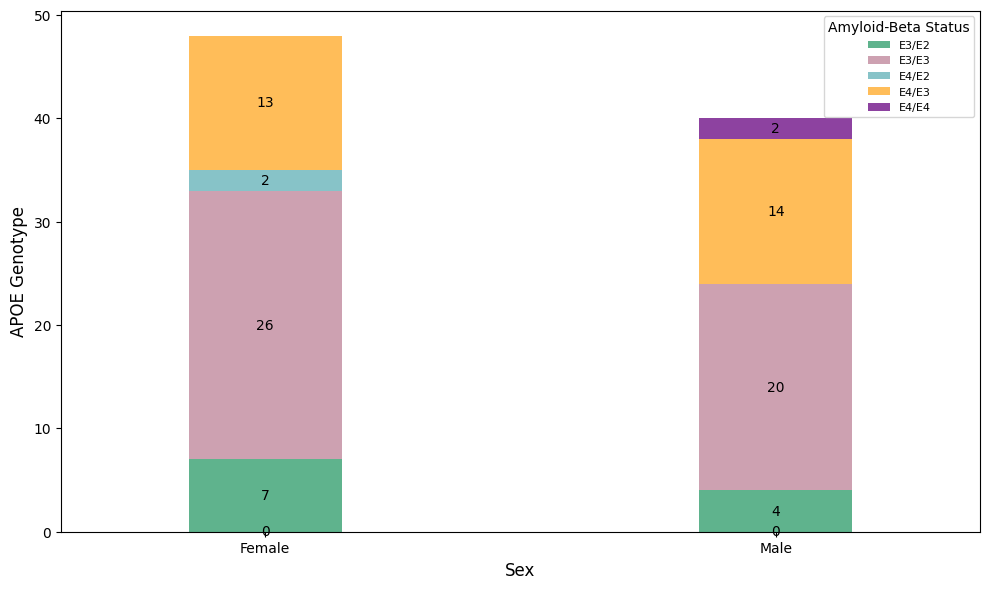

In [7]:
pivot_df_APOE = basic_statis_info_df_APOE.groupby(['Demographic.Sex', 'Demographic.ApoE genotype']).size().unstack(fill_value=0)

colors = ['#5fb38d', '#cda1b1', '#87c3c8','#ffbd59','#8d42a0'] 
ax = pivot_df_APOE.plot(kind='bar', stacked=True, figsize=(10, 6), color=colors, width=0.3)
plt.xlabel('Sex', fontsize=12)
plt.ylabel('APOE Genotype', fontsize=12)
plt.legend(title='Amyloid-Beta Status', title_fontsize='10', fontsize='8')

# Rotate x-axis labels for better readability
plt.xticks(rotation=0)

# Add value labels on the bars
for c in ax.containers:
    ax.bar_label(c, label_type='center')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

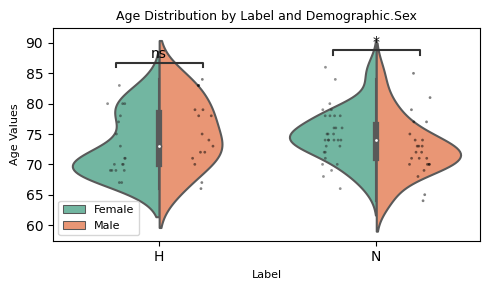

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# Assuming 'check_centiloid' is your DataFrame and contains columns 'label', 'Image.PET.Centiloid', and 'Gender'

feature_name = 'Age'
hue_name = 'Demographic.Sex'

plt.figure(figsize=(5, 3))
ax = sns.violinplot(x='label', y=feature_name, data=basic_statis_info_df_APOE, hue=hue_name, split=True, palette="Set2")

# Stripplot without adding to the legend
strip = sns.stripplot(x='label', y=feature_name, data=basic_statis_info_df_APOE, hue=hue_name, color='k', size=2, alpha=0.5, dodge=True)
strip.legend_.remove()  # Remove legend for stripplot

labels = basic_statis_info_df_APOE['label'].unique()
hues = basic_statis_info_df_APOE[hue_name].unique()
pairs = [((label, hues[0]), (label, hues[1])) for label in labels]

annotator = Annotator(ax, pairs, data=basic_statis_info_df_APOE, x='label', y=feature_name, hue=hue_name)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0, line_offset=0.05)
annotator.apply_and_annotate()

ax.set_title(f'{feature_name} Distribution by Label and {hue_name}', fontsize=9)
ax.set_xlabel('Label', fontsize=8)
ax.set_ylabel(f'{feature_name} Values', fontsize=8)

# Adjust legend for violinplot only
handles, labels = ax.get_legend_handles_labels()
n = len(basic_statis_info_df_APOE[hue_name].unique())  # number of hue categories
plt.legend(handles[:n], labels[:n], loc='best', fontsize=8)  # Show legend only for violinplot hues

plt.tight_layout()
plt.show()

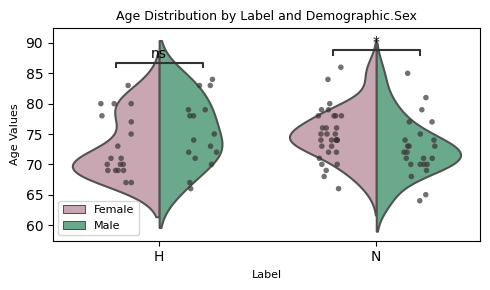

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# Assuming 'basic_statis_info_df_APOE' is your DataFrame and contains columns 'label', 'Age', and 'Demographic.Sex'

feature_name = 'Age'
hue_name = 'Demographic.Sex'

plt.figure(figsize=(5, 3))

violin_palette = {"Male": "#5fb38d", "Female": "#cda1b1"}  # Define custom colors for the outline

# Violinplot with transparent interior (no color) and colored outline
ax = sns.violinplot(x='label', y=feature_name, data=basic_statis_info_df_APOE, hue=hue_name, split=True, 
                    palette=violin_palette, inner=None, linewidth=1.5, facecolor=(0, 0, 0, 0))  # Transparent fill, colored outline


# Custom colors for stripplot dots
strip_palette = {"Male": "#3a3434", "Female": "#3a3434"}  # Define custom colors for dots

# Stripplot with custom colors for dots
strip = sns.stripplot(x='label', y=feature_name, data=basic_statis_info_df_APOE, hue=hue_name, 
                      palette=strip_palette, size=4, alpha=0.7, dodge=True, jitter=0.15)  # Larger dots, less jitter
strip.legend_.remove()  # Remove legend for stripplot

# Get unique labels and hues
labels = basic_statis_info_df_APOE['label'].unique()
hues = basic_statis_info_df_APOE[hue_name].unique()

# Define pairs for annotation
pairs = [((label, hues[0]), (label, hues[1])) for label in labels]

# Annotator configuration
annotator = Annotator(ax, pairs, data=basic_statis_info_df_APOE, x='label', y=feature_name, hue=hue_name)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0, line_offset=0.05)
annotator.apply_and_annotate()

# Customize title and axis labels
ax.set_title(f'{feature_name} Distribution by Label and {hue_name}', fontsize=9)
ax.set_xlabel('Label', fontsize=8)
ax.set_ylabel(f'{feature_name} Values', fontsize=8)

# Adjust legend to show for the violin plot hues only
handles, labels = ax.get_legend_handles_labels()
n = len(basic_statis_info_df_APOE[hue_name].unique())  # Number of hue categories
plt.legend(handles[:n], labels[:n], loc='best', fontsize=8)  # Show legend only for violinplot hues

plt.tight_layout()
plt.show()


In [10]:
basic_statistics_ft = ['Demographic.Years of Education Exact', 'Age', 'Demographic.Sex', 'Demographic.ApoE genotype', 'label','AIBL.ID','Collection']
basic_statis_info_df = omics_with_demo_df[basic_statistics_ft]
# basic_statis_info_df['Demographic.ApoE genotype'] = basic_statis_info_df['Demographic.ApoE genotype'].str.contains('E4', na=False).astype(int)
basic_statis_info_df['APOE4'] = np.where(
basic_statis_info_df['Demographic.ApoE genotype'].str.contains('E4', na=False),
    1,
    np.where(basic_statis_info_df['Demographic.ApoE genotype'].isna(),np.nan,0)
)

In [11]:
plus_minus = '\u00B1'
def calculate_stats(df, df_name):
    female_count = df[df['Demographic.Sex'] == "Female"].shape[0]
    female_proportion = round((female_count/df.shape[0])* 100,2)
    apoe_counts = df[df['APOE4']== 1].shape[0]
    apoe_proportions = round((apoe_counts / df.shape[0])*100, 2)
    
    age_mean = round(df['Age'].mean(), 2)
    age_std = round(df['Age'].std(), 2)


    Edu_mean = round(df['Demographic.Years of Education Exact'].mean(), 2)
    Edu_std = round(df['Demographic.Years of Education Exact'].std(), 2)

    
   
    return {"Group Name":f"{df_name} (n={df.shape[0]})",
           "Sex": f'{female_count} ({female_proportion}%)',
           "Age": f"{age_mean} {plus_minus} {age_std}",
           "APOE4": f'{apoe_counts} ({apoe_proportions}%)',
           "Education (year)": f"{Edu_mean} {plus_minus} {Edu_std}"
        #    "CDR final": f"{cdr_end_mean} {plus_minus} {cdr_end_std}",
           }


datasets = [(basic_statis_info_df, "Full dataset"), 
            (basic_statis_info_df[basic_statis_info_df['label']=="H"], "Amyloid-beta High"),
            (basic_statis_info_df[basic_statis_info_df['label']=="N"], "Amyloid-beta Normal")]
summary_stats = pd.DataFrame()
for (cur_df, cur_df_name) in datasets:
    summary_stats = pd.concat([summary_stats, pd.DataFrame([calculate_stats(cur_df, cur_df_name)])], ignore_index=True)
summary_stats

,Group Name,Sex,Age,APOE4,Education (year)
0,Full dataset (n=90),50 (55.56%),73.97 ± 4.87,31 (34.44%),13.42 ± 2.87
1,Amyloid-beta High (n=35),19 (54.29%),74.06 ± 5.35,16 (45.71%),13.1 ± 2.71
2,Amyloid-beta Normal (n=55),31 (56.36%),73.91 ± 4.6,15 (27.27%),13.6 ± 2.96


In [12]:
pd.crosstab(basic_statis_info_df['label'], basic_statis_info_df['APOE4'])

APOE4,0.0,1.0
label,,
H,17,16
N,40,15


In [13]:
basic_statis_info_df

,Demographic.Years of Education Exact,Age,Demographic.Sex,Demographic.ApoE genotype,label,AIBL.ID,Collection,APOE4
0,15.0,69.0,Female,E4/E2,H,837,7,1.0
1,NaN,67.0,Female,NaN,H,2276,1,NaN
2,10.0,67.0,Female,E4/E3,H,2274,1,1.0
3,10.0,69.0,Female,E4/E3,H,2321,1,1.0
4,NaN,70.0,Female,E3/E3,H,2326,1,0.0
...,...,...,...,...,...,...,...,...
85,20.0,75.0,Male,E3/E3,N,859,8,0.0
86,NaN,68.0,Male,E4/E3,N,2332,2,1.0
87,11.0,74.0,Male,E4/E3,N,1514,5,1.0
88,15.0,73.0,Male,E4/E3,N,2077,3,1.0


In [14]:
plus_minus = '\u00B1'
def calculate_stats_sex(df, df_name):
    amyloid_high_count = df[df['label'] == 'H'].shape[0]
    amyloid_high_proportion = round((amyloid_high_count/df.shape[0])* 100,2)
    apoe_counts = df[df['APOE4']== 1].shape[0]
    apoe_proportions = round((apoe_counts / df.shape[0])*100, 2)
    
    age_mean = round(df['Age'].mean(), 2)
    age_std = round(df['Age'].std(), 2)


    Edu_mean = round(df['Demographic.Years of Education Exact'].mean(), 2)
    Edu_std = round(df['Demographic.Years of Education Exact'].std(), 2)

    
   
    return {"Group Name":f"{df_name} (n={df.shape[0]})",
           "Amyloid High": f'{amyloid_high_count} ({amyloid_high_proportion}%)',
           "Age": f"{age_mean} {plus_minus} {age_std}",
           "APOE4": f'{apoe_counts} ({apoe_proportions}%)',
           "Education (year)": f"{Edu_mean} {plus_minus} {Edu_std}"
        #    "CDR final": f"{cdr_end_mean} {plus_minus} {cdr_end_std}",
           }

datasets = [(basic_statis_info_df, "Full dataset"), 
            (basic_statis_info_df[basic_statis_info_df['Demographic.Sex']=="Female"], "Female"),
            (basic_statis_info_df[basic_statis_info_df['Demographic.Sex']=="Male"], "Male")]
summary_stats = pd.DataFrame()
for (cur_df, cur_df_name) in datasets:
    summary_stats = pd.concat([summary_stats, pd.DataFrame([calculate_stats_sex(cur_df, cur_df_name)])], ignore_index=True)
summary_stats

,Group Name,Amyloid High,Age,APOE4,Education (year)
0,Full dataset (n=90),35 (38.89%),73.97 ± 4.87,31 (34.44%),13.42 ± 2.87
1,Female (n=50),19 (38.0%),74.18 ± 4.66,15 (30.0%),13.17 ± 2.88
2,Male (n=40),16 (40.0%),73.7 ± 5.18,16 (40.0%),13.75 ± 2.86


In [29]:
print(omics_with_demo_df.select_dtypes(include=['object', 'category']).columns)

Index(['label', 'Demographic.ApoE genotype', 'Demographic.Years of Education',
       'Demographic.Sex', 'Demographic.Primary Occupation',
       'Demographic.Retirement Status', 'Demographic.Current Marital Status',
       'Demographic.Country of Birth', 'Demographic.Handedness'],
      dtype='object')


In [10]:
omics_df_normalise = omics_with_demo_df.copy()
omics_df_normalise['label'] = omics_df_normalise['label'].replace({"H": 1, "N": 0})
omics_df_normalise['Demographic.Sex'] = omics_df_normalise['Demographic.Sex'].replace({"Male": 1, "Female": 0})
#omics_df_normalise.rename(columns={col: col.replace(':', '_') for col in omics_df_normalise.columns if ':' in col}, inplace=True)


columns_to_drop = omics_df_normalise[['label', 'Demographic.ApoE genotype', 'Demographic.Years of Education','Demographic.Sex']]
omics_df_normalise = omics_df_normalise.drop(['label', 'Demographic.ApoE genotype', 'Demographic.Years of Education','Demographic.Sex'], axis=1)
print("Shape after dropping specified columns:", omics_df_normalise.shape)




# # ##### MinMax scaling
# scaler = StandardScaler()
scaler = MinMaxScaler()
normalized_features = pd.DataFrame(scaler.fit_transform(omics_df_normalise), columns=omics_df_normalise.columns)

omics_demo_normalise_df = pd.concat([columns_to_drop, normalized_features], axis=1)
omics_demo_normalise_df.head(2)

Shape after dropping specified columns: (90, 1908)


,label,Demographic.ApoE genotype,Demographic.Years of Education,Demographic.Sex,Acetone cyanohydrin,Acetone cyanohydrin.1,Diacetyl,2-Butyne-1_4-diol,2-Butyne-1_4-diol.1,2-Aminoacrylic acid,...,VCL,VNN1,VSIG4,VTN,VWF,YWHAZ,Collection,APOE4,Demographic.Years of Education Exact,Age
0,1,E4/E2,13-15,0,0.206901,0.316707,0.446643,0.251892,0.354579,0.721714,...,0.548556,0.015636,0.623655,0.563358,0.573927,0.560821,0.6,1.0,0.545455,0.227273
1,1,NaN,15+,0,0.300413,0.262732,0.278469,0.295970,0.245188,0.563264,...,0.443304,0.367330,0.625328,0.210435,0.331067,0.549499,0.0,NaN,NaN,0.136364


In [11]:
omics_df_normalise_no_missing = pd.read_csv('../data/merged_data/omics_aibl_demo_no_missing.csv',index_col=0)
omics_df_normalise_no_missing = omics_df_normalise_no_missing.drop(['Gender'], axis=1)
omics_df_normalise_no_missing['label'] = omics_df_normalise_no_missing['label'].replace({"H": 1, "N": 0})
omics_df_normalise_no_missing['Demographic.Sex'] = omics_df_normalise_no_missing['Demographic.Sex'].replace({"Male": 1, "Female": 0})
#omics_df_normalise_no_missing.rename(columns={col: col.replace(':', '_') for col in omics_df_normalise.columns if ':' in col}, inplace=True)


columns_to_drop_no_missing = omics_df_normalise_no_missing[['label', 'APOE4','Demographic.Sex']]
omics_df_normalise_no_missing = omics_df_normalise_no_missing.drop(['label', 'APOE4','Demographic.Sex'], axis=1)
print("Shape after dropping specified columns:", omics_df_normalise_no_missing.shape)

# # ##### MinMax scaling
# scaler = StandardScaler()
scaler = MinMaxScaler()
normalized_features_no_missing = pd.DataFrame(scaler.fit_transform(omics_df_normalise_no_missing), columns=omics_df_normalise_no_missing.columns)

omics_demo_normalise_df_no_missing = pd.concat([columns_to_drop_no_missing, normalized_features_no_missing], axis=1)
omics_demo_normalise_df_no_missing.head(2)

Shape after dropping specified columns: (90, 1907)


,label,APOE4,Demographic.Sex,Acetone cyanohydrin,Acetone cyanohydrin.1,Diacetyl,2-Butyne-1_4-diol,2-Butyne-1_4-diol.1,2-Aminoacrylic acid,Malonic semialdehyde,...,VCAM1,VCL,VNN1,VSIG4,VTN,VWF,YWHAZ,Collection,Demographic.Years of Education Exact,Age
0,1,1.0,0,0.206901,0.316707,0.446643,0.251892,0.354579,0.721714,0.309543,...,0.449129,0.548556,0.015636,0.623655,0.563358,0.573927,0.560821,0.6,0.545455,0.227273
1,1,0.0,0,0.300413,0.262732,0.278469,0.295970,0.245188,0.563264,0.188008,...,0.443178,0.443304,0.367330,0.625328,0.210435,0.331067,0.549499,0.0,0.545455,0.136364


#### PCA plots

No exact elbow

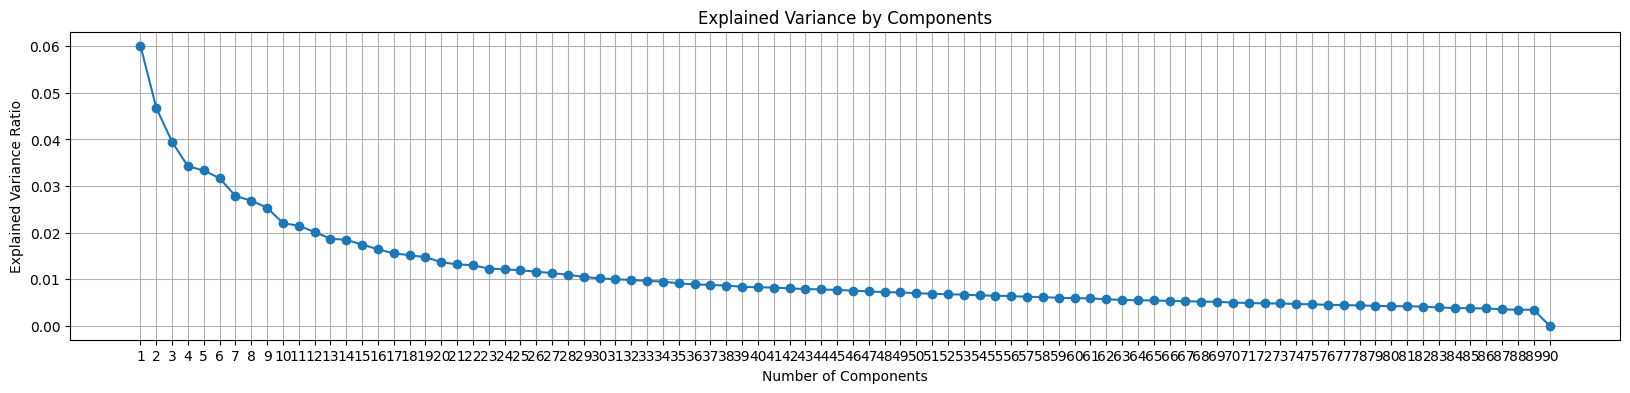

In [12]:
pca = PCA()
pca.fit(normalized_features_no_missing)

# Get the explained variance ratio
explained_variance = pca.explained_variance_ratio_

# Plotting the explained variance
plt.figure(figsize=(20, 4))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o')
plt.title('Explained Variance by Components')
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance Ratio')
plt.xticks(range(1, len(explained_variance) + 1))  # Ensure x-ticks match the number of components
plt.grid(True)
plt.show()

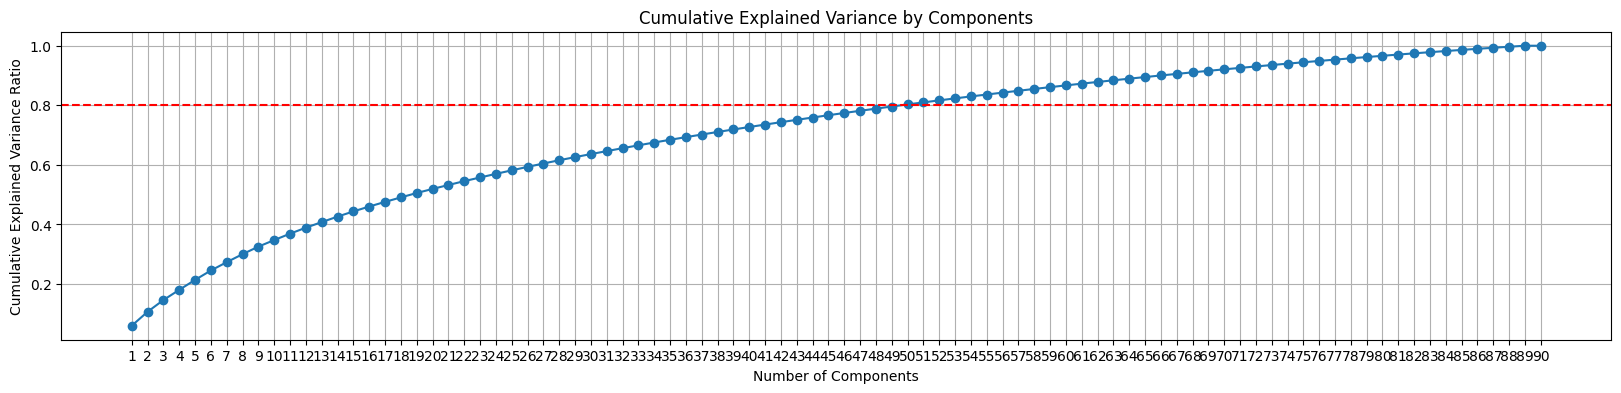

In [13]:
# cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

cumulative_variance = np.cumsum(explained_variance)
# Plotting the cumulative explained variance
plt.figure(figsize=(20, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.title('Cumulative Explained Variance by Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.xticks(range(1, len(cumulative_variance) + 1)) 
plt.grid(True)
plt.axhline(y=0.8, color='r', linestyle='--')
plt.show()

#### Volcano plot

In [14]:
omics_df_vol = omics_demo_normalise_df_no_missing.copy()
condition_H = omics_df_vol[omics_df_vol['label'] == 1].drop(columns='label')
condition_N = omics_df_vol[omics_df_vol['label'] == 0].drop(columns='label')
log2_fold_changes = []
p_values = []

for feature in condition_H.columns:
    mean_H = condition_H[feature].mean()
    mean_N = condition_N[feature].mean()
    log2_fc = np.log2(mean_H / mean_N)
    log2_fold_changes.append(log2_fc)
    
    # T-test
    _, p_value = ttest_ind(condition_H[feature], condition_N[feature])
    p_values.append(p_value)

# Create a DataFrame for the results
results_df = pd.DataFrame({
    'feature': condition_H.columns,
    'log2FoldChange': log2_fold_changes,
    'pvalue': p_values
})

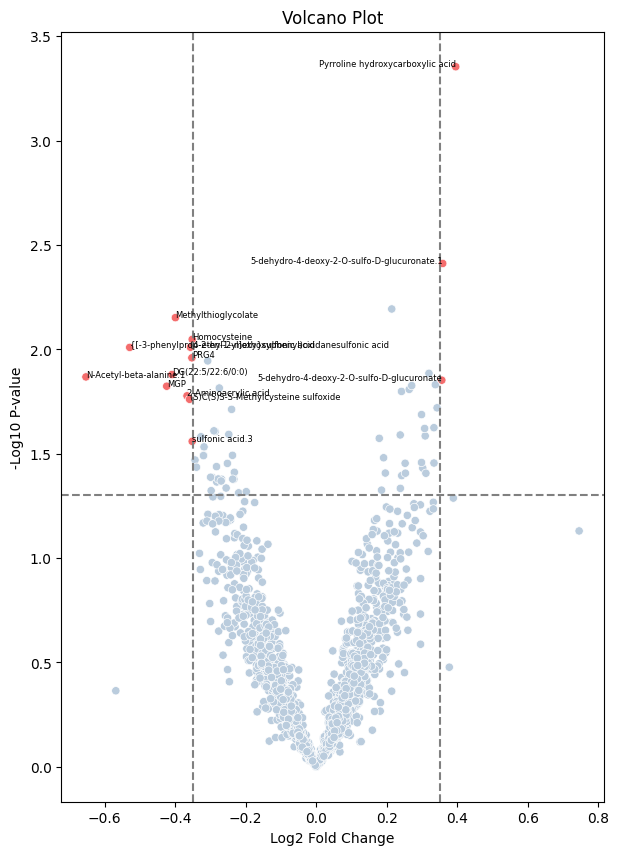

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
pvalue_threshold = 0.05
log2fc_threshold = 0.35

# Create a new column to define colors based on significance
results_df['color'] = '#BACCDD'  # Not significant
results_df.loc[(results_df['pvalue'] < pvalue_threshold) & (abs(results_df['log2FoldChange']) > log2fc_threshold), 'color'] = '#F46D6D'

# Create plot
plt.figure(figsize=(7, 10))
sns.scatterplot(x='log2FoldChange', y=-np.log10(results_df['pvalue']), data=results_df, hue='color', palette={'#BACCDD': '#BACCDD', '#F46D6D': '#F46D6D'}, legend=False)
plt.xlabel('Log2 Fold Change')
plt.ylabel('-Log10 P-value')
plt.title('Volcano Plot')

# Add threshold lines
plt.axhline(-np.log10(pvalue_threshold), color='gray', linestyle='--')
plt.axvline(log2fc_threshold, color='gray', linestyle='--')
plt.axvline(-log2fc_threshold, color='gray', linestyle='--')

# Annotate significant points
for i, row in results_df.iterrows():
    if row['color'] == '#F46D6D':
        ha = 'right' if row['log2FoldChange'] > log2fc_threshold else 'left'
        plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha=ha)

# for i, row in results_df.iterrows():
#     if row['color'] == '#DDBABA':
#         plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha='left')
plt.savefig("../plots/volcano_plot.png", bbox_inches='tight')
plt.show()


In [16]:
df_sorted = results_df.sort_values(by='pvalue', ascending=True)
df_sorted.head(10)

,feature,log2FoldChange,pvalue,color
117,Pyrroline hydroxycarboxylic acid,0.395401,0.000442,#F46D6D
723,5-dehydro-4-deoxy-2-O-sulfo-D-glucuronate.1,0.358491,0.003874,#F46D6D
11,Butyric acid.1,0.213959,0.006402,#BACCDD
233,Methylthioglycolate,-0.399415,0.007044,#F46D6D
161,Homocysteine,-0.351756,0.008954,#F46D6D
637,(4-ethyl-2-methoxyphenyl)oxidanesulfonic acid,-0.356825,0.009765,#F46D6D
550,{[-3-phenylprop-2-en-1-yl]oxy}sulfonic acid,-0.528927,0.009782,#F46D6D
1804,PRG4,-0.352655,0.010973,#F46D6D
79,Dihydro-4-mercapto-3(2H)-furanone,-0.307752,0.011353,#BACCDD
456,2-carboxy-L-xylonolactone.1,0.319450,0.013022,#BACCDD


In [16]:
results_df[results_df['feature']=='APOE4']

,feature,log2FoldChange,pvalue,color
0,APOE4,0.745186,0.074112,#BACCDD


#### Heatmap

In [17]:
feature_type_df = pd.read_csv('../data/merged_data/feature_type.csv',index_col=0)
result_for_heatmap = pd.merge(results_df, feature_type_df, on=['feature'],how='inner')

<Figure size 1400x1000 with 0 Axes>

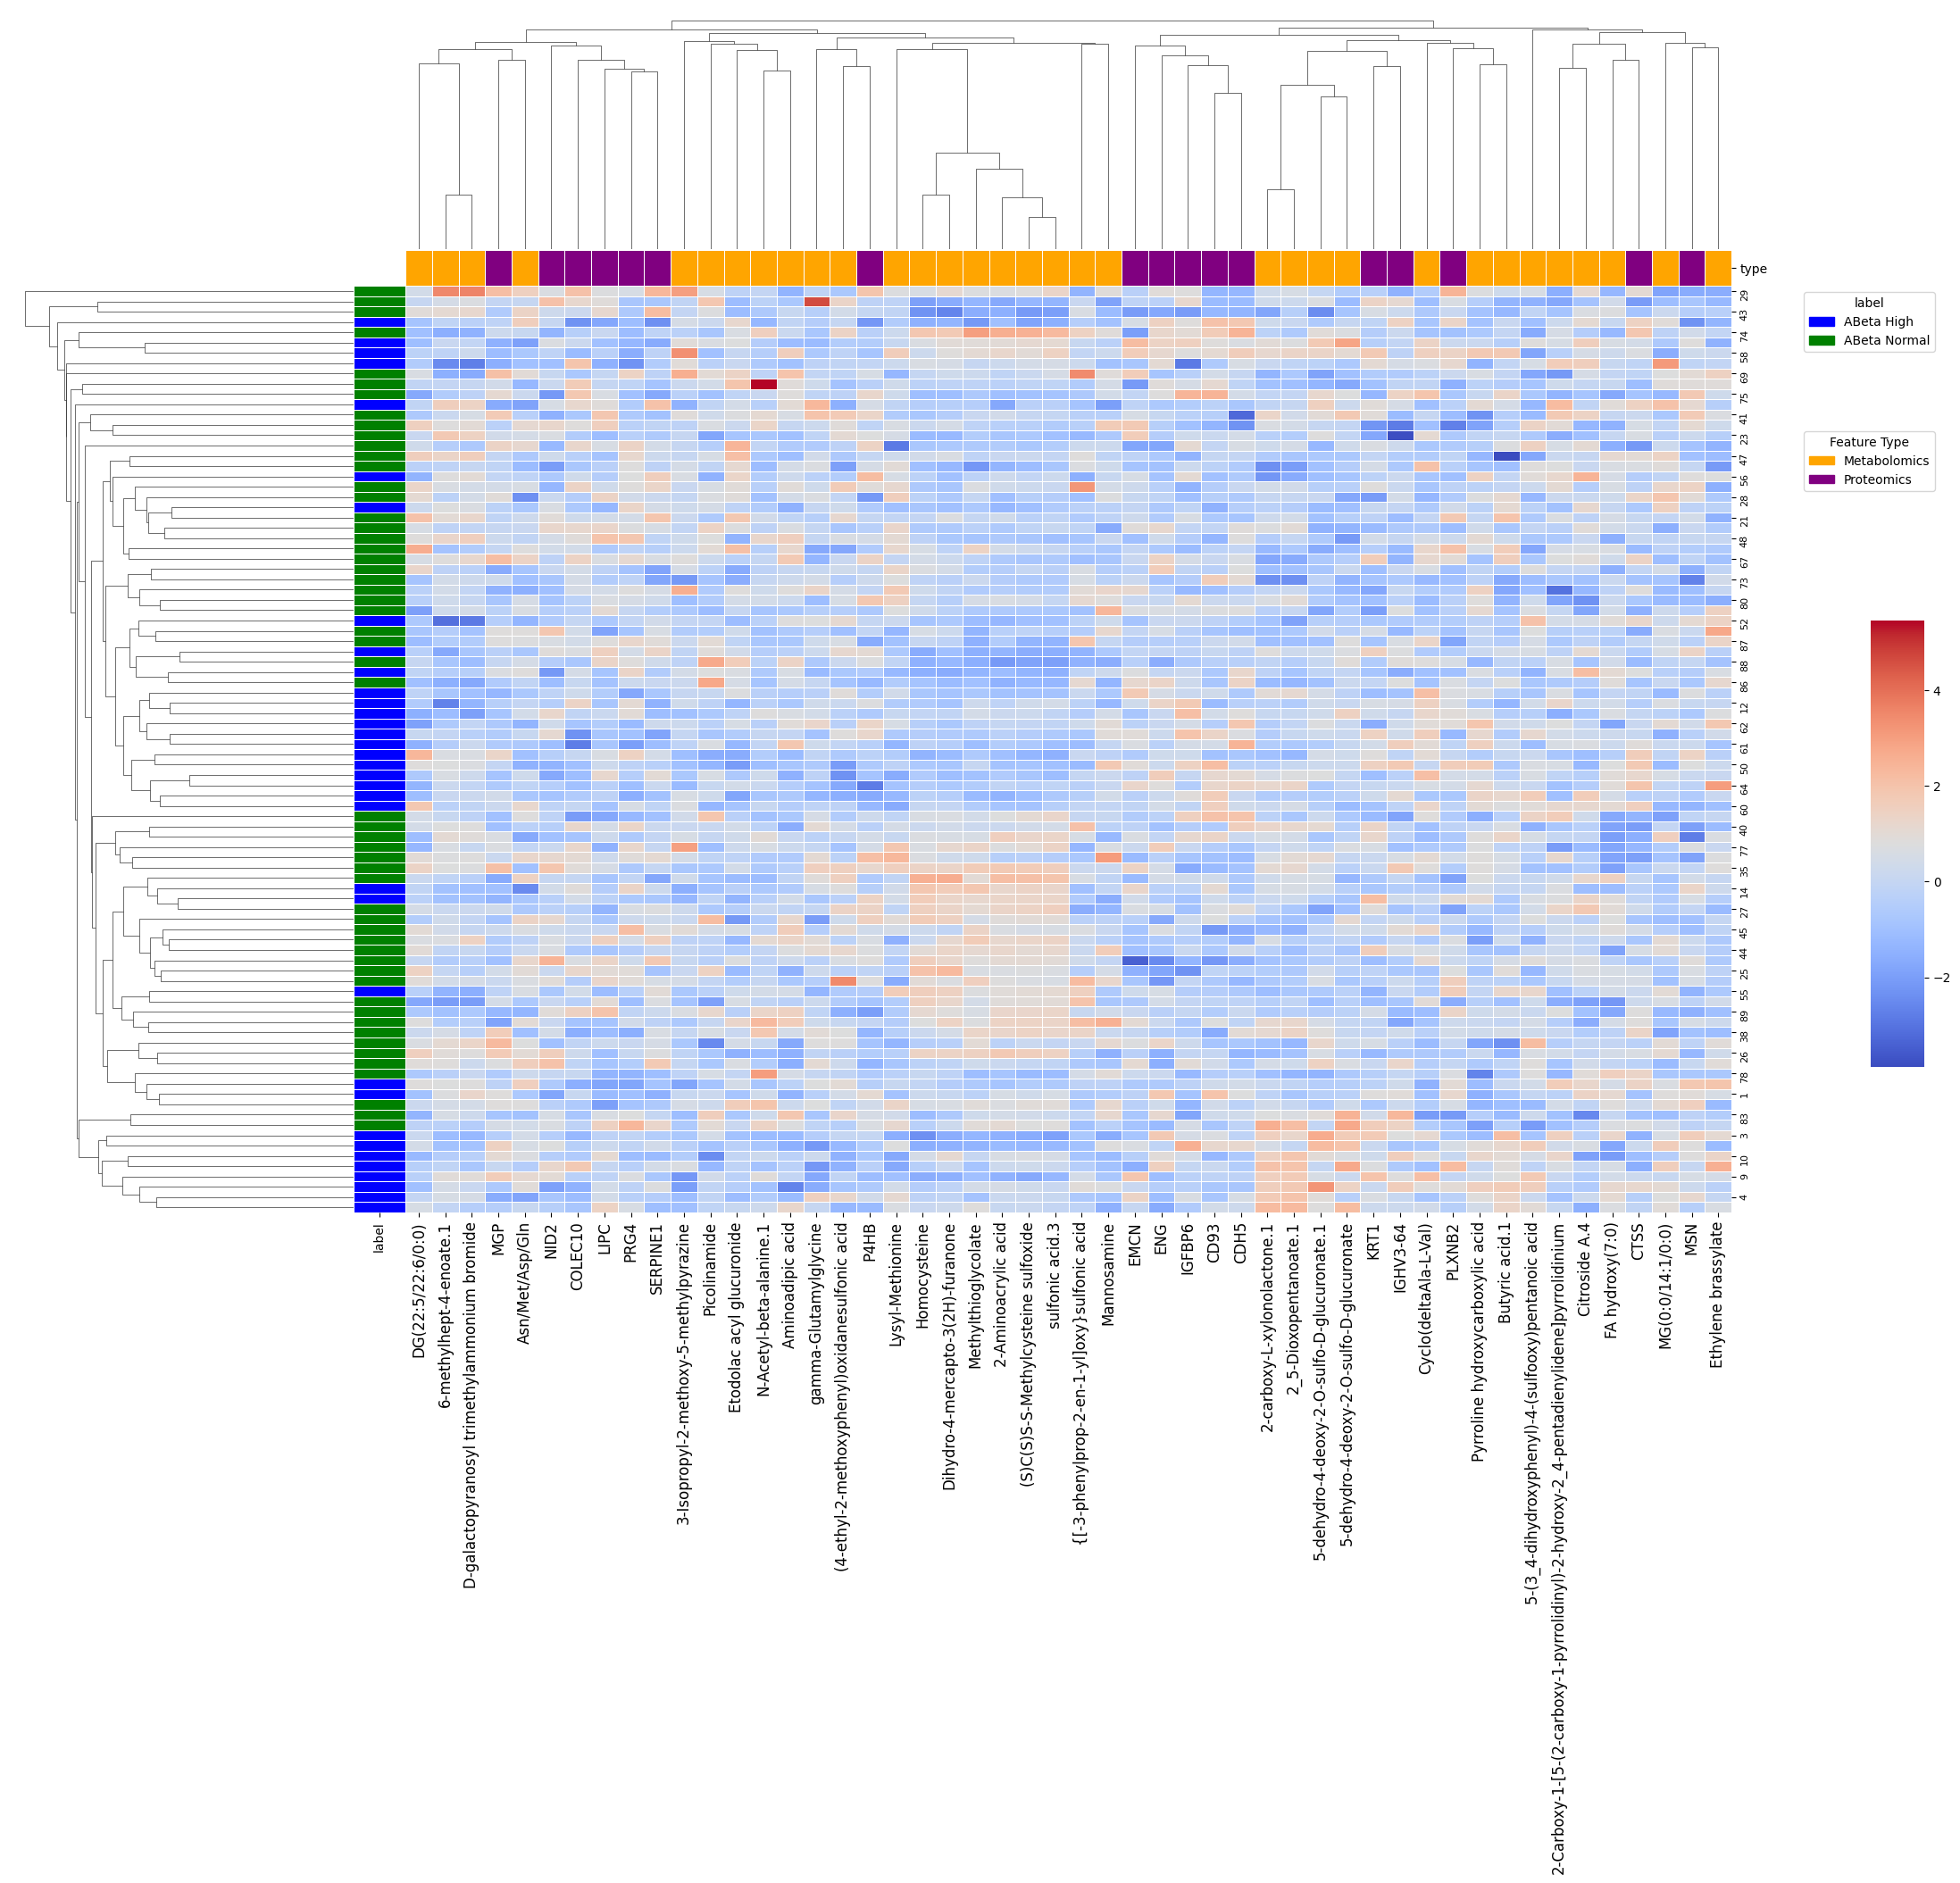

In [19]:
top_50_features = result_for_heatmap.nsmallest(50, 'pvalue')['feature'].values
heatmap_data = omics_df_vol[top_50_features]
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()

# Add a condition column to heatmap_data for annotation
omics_df_vol['label']=omics_df_vol['label'].replace({1: 'ABeta High', 0: 'ABeta Normal'})
heatmap_data['label'] = omics_df_vol['label']

# Reorder the columns to move 'condition' to the beginning
cols = heatmap_data.columns.tolist()
cols = cols[-1:] + cols[:-1]
heatmap_data = heatmap_data[cols]

# Create a color bar for the feature types
feature_types = result_for_heatmap.set_index('feature').loc[top_50_features, 'type']
feature_type_colors = feature_types.map({'metabolomics': 'orange', 'proteomics': 'purple'})


plt.figure(figsize=(14, 10))

# Create row and column linkage matrices for clustering
row_linkage = linkage(heatmap_data.drop(columns='label'), method='average')
col_linkage = linkage(heatmap_data.drop(columns='label').T, method='average')

# Create the clustermap
g = sns.clustermap(
    heatmap_data.drop(columns='label'), 
    row_linkage=row_linkage, 
    col_linkage=col_linkage, 
    cmap='coolwarm', 
    linewidths=0.5,
    figsize=(20, 20),
    row_colors=heatmap_data['label'].map({'ABeta High': 'blue', 'ABeta Normal': 'green'}),
    col_colors=feature_type_colors,
    cbar_pos=(1.05, 0.4, 0.03, 0.25)  # Adjusting colorbar position
)

g.ax_heatmap.tick_params(axis='x', labelsize=12)
g.ax_heatmap.tick_params(axis='y', labelsize=8)

# Create legend handles
condition_legend = [Patch(facecolor='blue', edgecolor='blue', label='ABeta High'),
                    Patch(facecolor='green', edgecolor='green', label='ABeta Normal')]
feature_type_legend = [Patch(facecolor='orange', edgecolor='orange', label='Metabolomics'),
                       Patch(facecolor='purple', edgecolor='purple', label='Proteomics')]

# Add legends to the plot
legend1 = g.ax_heatmap.legend(handles=condition_legend, title='label', loc='upper left', bbox_to_anchor=(1.05, 1))
legend2 = g.ax_heatmap.legend(handles=feature_type_legend, title='Feature Type', loc='upper left', bbox_to_anchor=(1.05, 0.85))

# Add both legends to the plot
g.ax_heatmap.add_artist(legend1)
plt.savefig("../plots/heatmap.png", bbox_inches='tight')
plt.show()

In [34]:
top_50_features_sorted

,feature,log2FoldChange,pvalue,color,type
133,N-Acetyl-beta-alanine.1,-0.652997,0.013546,#F46D6D,metabolomics
550,{[-3-phenylprop-2-en-1-yl]oxy}sulfonic acid,-0.528927,0.009782,#F46D6D,metabolomics
1736,MGP,-0.424059,0.015010,#F46D6D,proteomics
1326,DG(22:5/22:6/0:0),-0.409215,0.013194,#F46D6D,metabolomics
233,Methylthioglycolate,-0.399415,0.007044,#F46D6D,metabolomics
7,2-Aminoacrylic acid,-0.366463,0.016692,#F46D6D,metabolomics
229,(S)C(S)S-S-Methylcysteine sulfoxide,-0.359219,0.017341,#F46D6D,metabolomics
637,(4-ethyl-2-methoxyphenyl)oxidanesulfonic acid,-0.356825,0.009765,#F46D6D,metabolomics
1803,PRG4,-0.352655,0.010973,#F46D6D,proteomics
1066,sulfonic acid.3,-0.351768,0.027574,#F46D6D,metabolomics


<Figure size 1400x1000 with 0 Axes>

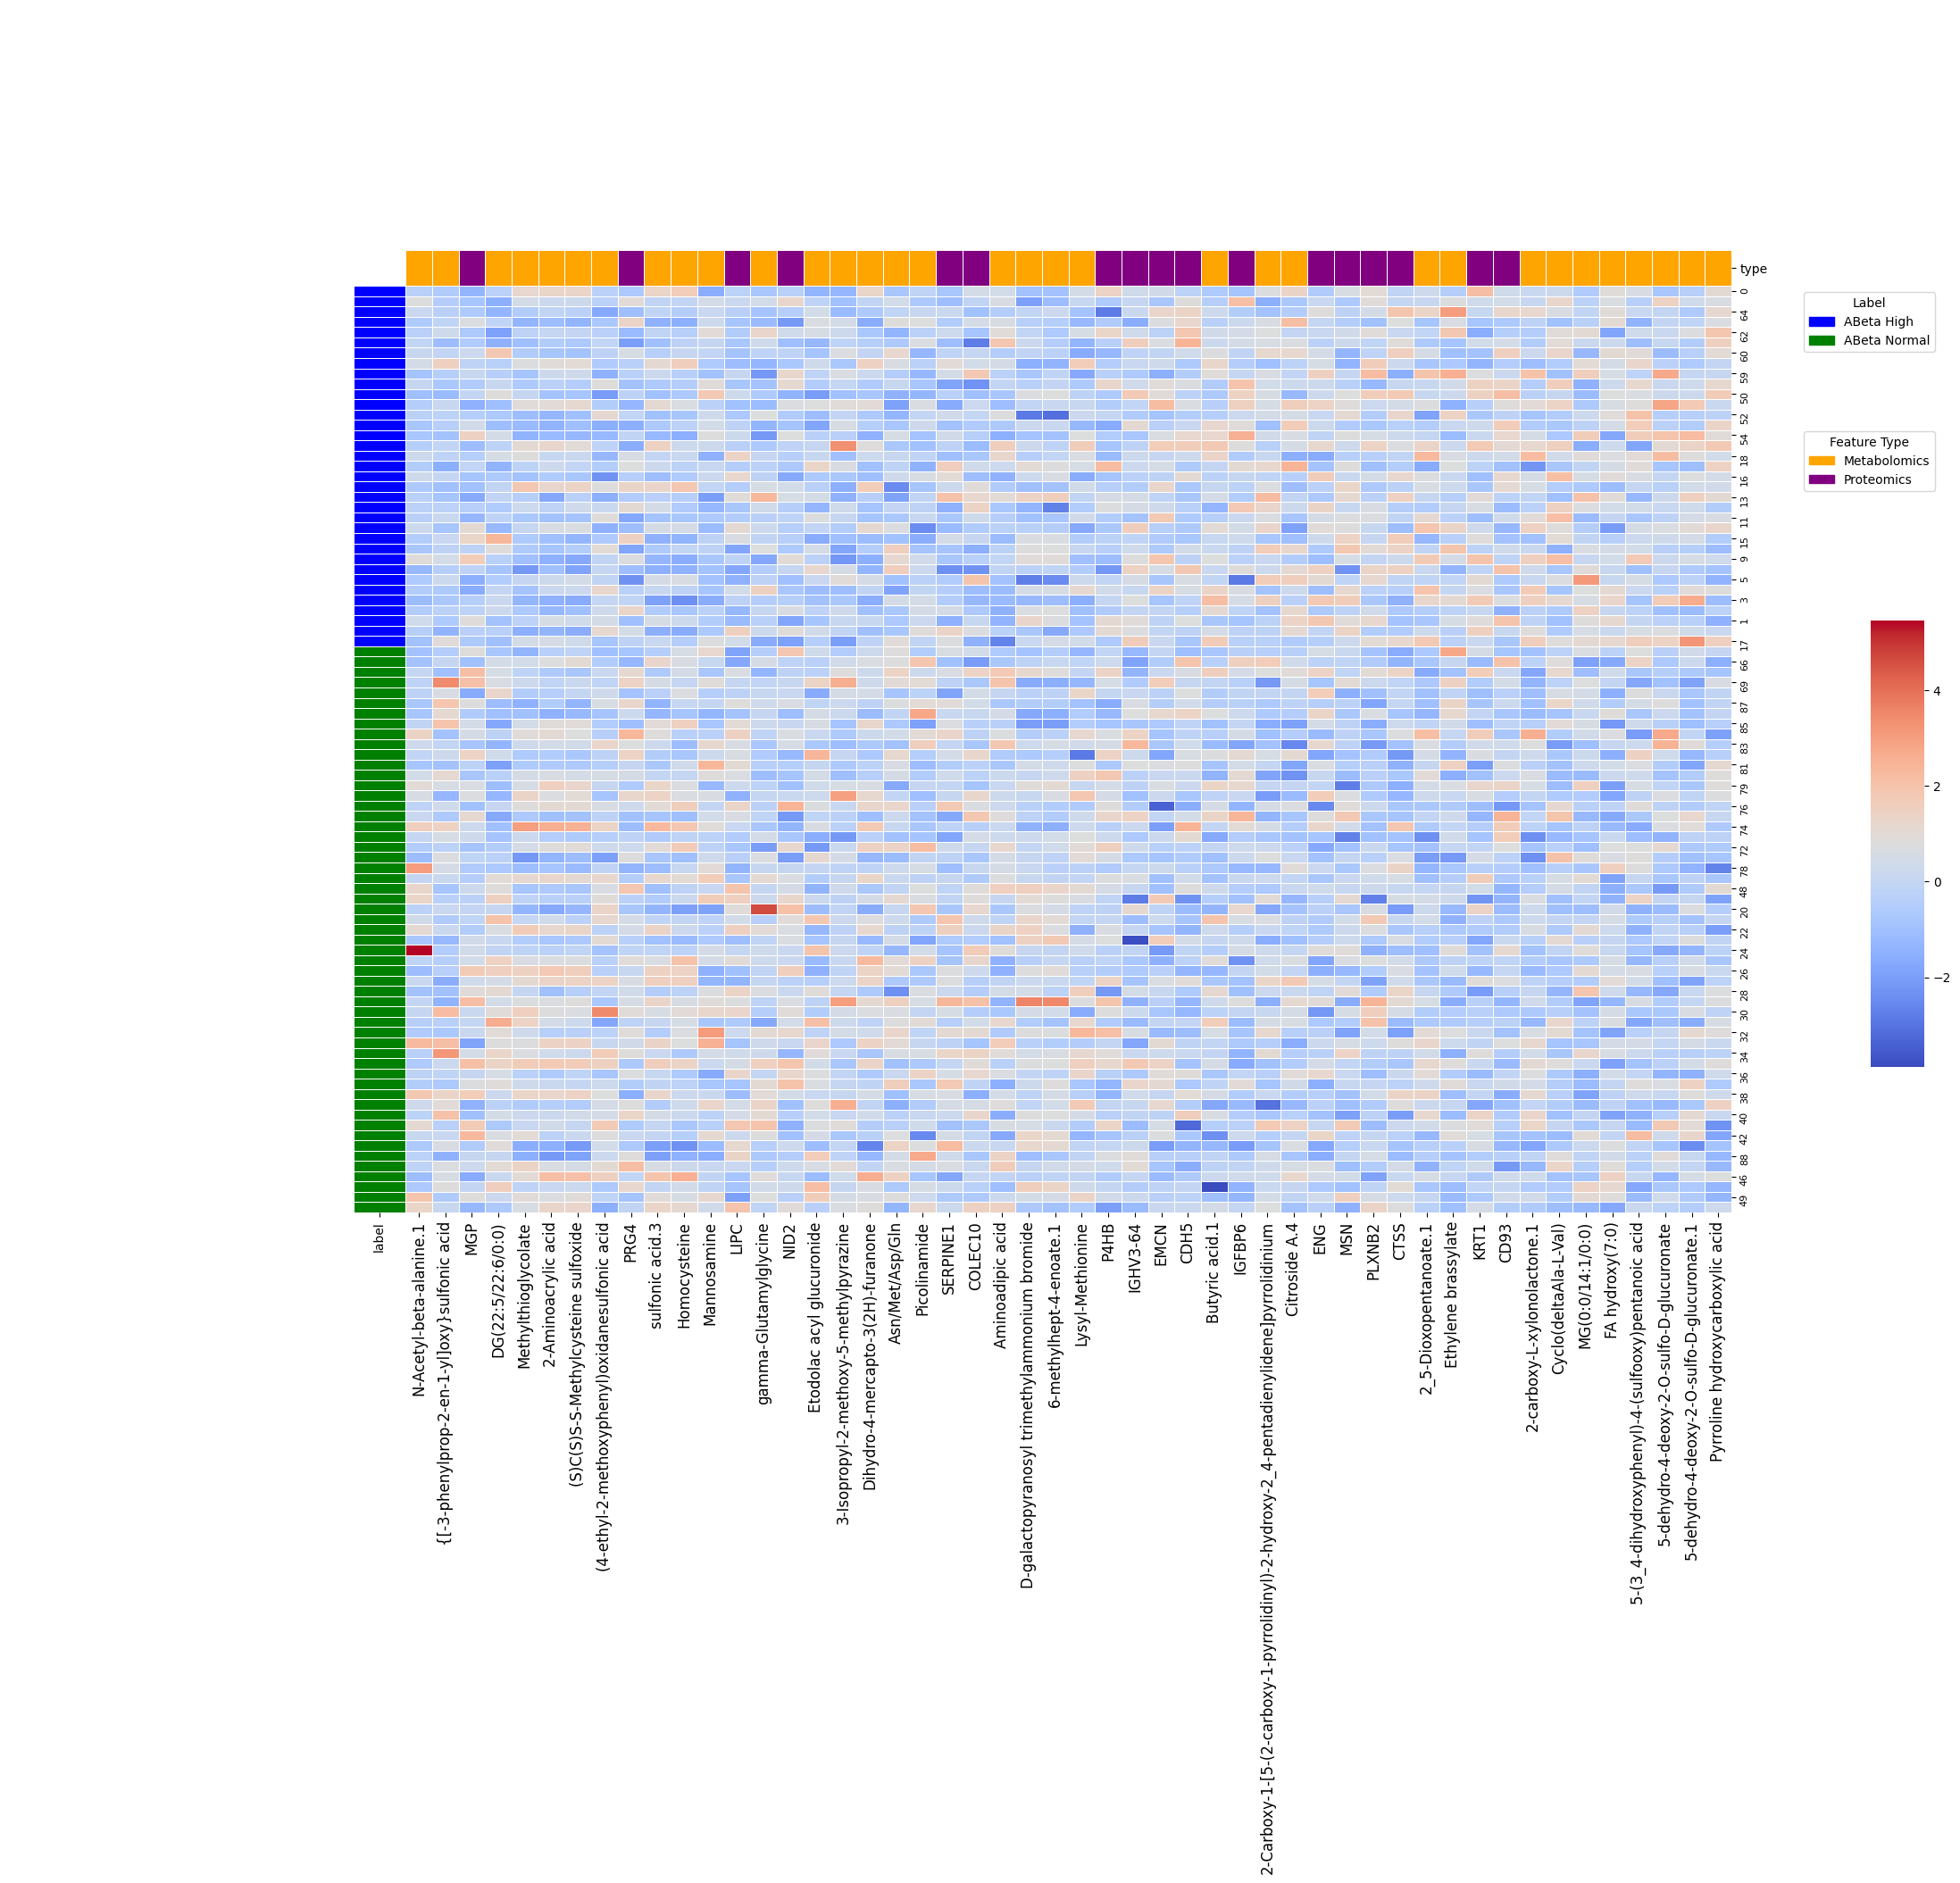

In [33]:
# Select the top 50 features by p-value
top_50_features = result_for_heatmap.nsmallest(50, 'pvalue')

# Sort these features from downregulation to upregulation by fold change
top_50_features_sorted = top_50_features.sort_values(by='log2FoldChange')

# Get the sorted feature names
sorted_feature_names = top_50_features_sorted['feature'].values

# Extract the heatmap data for these sorted features
heatmap_data = omics_df_vol[sorted_feature_names]
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()

# Update label for clarity in annotation
omics_df_vol['label'] = omics_df_vol['label'].replace({1: 'ABeta High', 0: 'ABeta Normal'})
heatmap_data['label'] = omics_df_vol['label']

# Reordering columns to move 'label' to the beginning for better visibility
cols = heatmap_data.columns.tolist()
cols = cols[-1:] + cols[:-1]
heatmap_data = heatmap_data[cols]
heatmap_data = heatmap_data.sort_values(by='label')

# Defining feature type colors
feature_types = result_for_heatmap.set_index('feature').loc[sorted_feature_names, 'type']
feature_type_colors = feature_types.map({'metabolomics': 'orange', 'proteomics': 'purple'})

plt.figure(figsize=(14, 10))

# Clustering
row_linkage = linkage(heatmap_data.drop(columns='label'), method='average')
col_linkage = linkage(heatmap_data.drop(columns='label').T, method='average')

# Generating clustermap
g = sns.clustermap(
    heatmap_data.drop(columns='label'),
    col_cluster=False,  # Already set to maintain column order
    row_cluster=False,  # Disable row clustering to maintain label sort order
    cmap='coolwarm',
    linewidths=0.5,
    figsize=(20, 20),
    row_colors=heatmap_data['label'].map({'ABeta High': 'blue', 'ABeta Normal': 'green'}),
    col_colors=feature_type_colors,
    cbar_pos=(1.05, 0.4, 0.03, 0.25)
)

# Adjusting tick parameters for better readability
g.ax_heatmap.tick_params(axis='x', labelsize=12)
g.ax_heatmap.tick_params(axis='y', labelsize=8)

# Creating legends for conditions and feature types
condition_legend = [Patch(facecolor='blue', edgecolor='blue', label='ABeta High'),
                    Patch(facecolor='green', edgecolor='green', label='ABeta Normal')]
feature_type_legend = [Patch(facecolor='orange', edgecolor='orange', label='Metabolomics'),
                       Patch(facecolor='purple', edgecolor='purple', label='Proteomics')]

# Adding legends to the plot
legend1 = g.ax_heatmap.legend(handles=condition_legend, title='Label', loc='upper left', bbox_to_anchor=(1.05, 1))
legend2 = g.ax_heatmap.legend(handles=feature_type_legend, title='Feature Type', loc='upper left', bbox_to_anchor=(1.05, 0.85))

# Ensuring both legends are added
g.ax_heatmap.add_artist(legend1)
plt.show()


In [22]:
top_50_features = result_for_heatmap.nsmallest(50, 'pvalue')['feature'].values
top_50_features = np.append(['label','Demographic.Sex'], top_50_features)
heatmap_data = omics_df_vol[top_50_features]
heatmap_data.to_csv("../statistics/heatmap_minimaxtop50.csv")


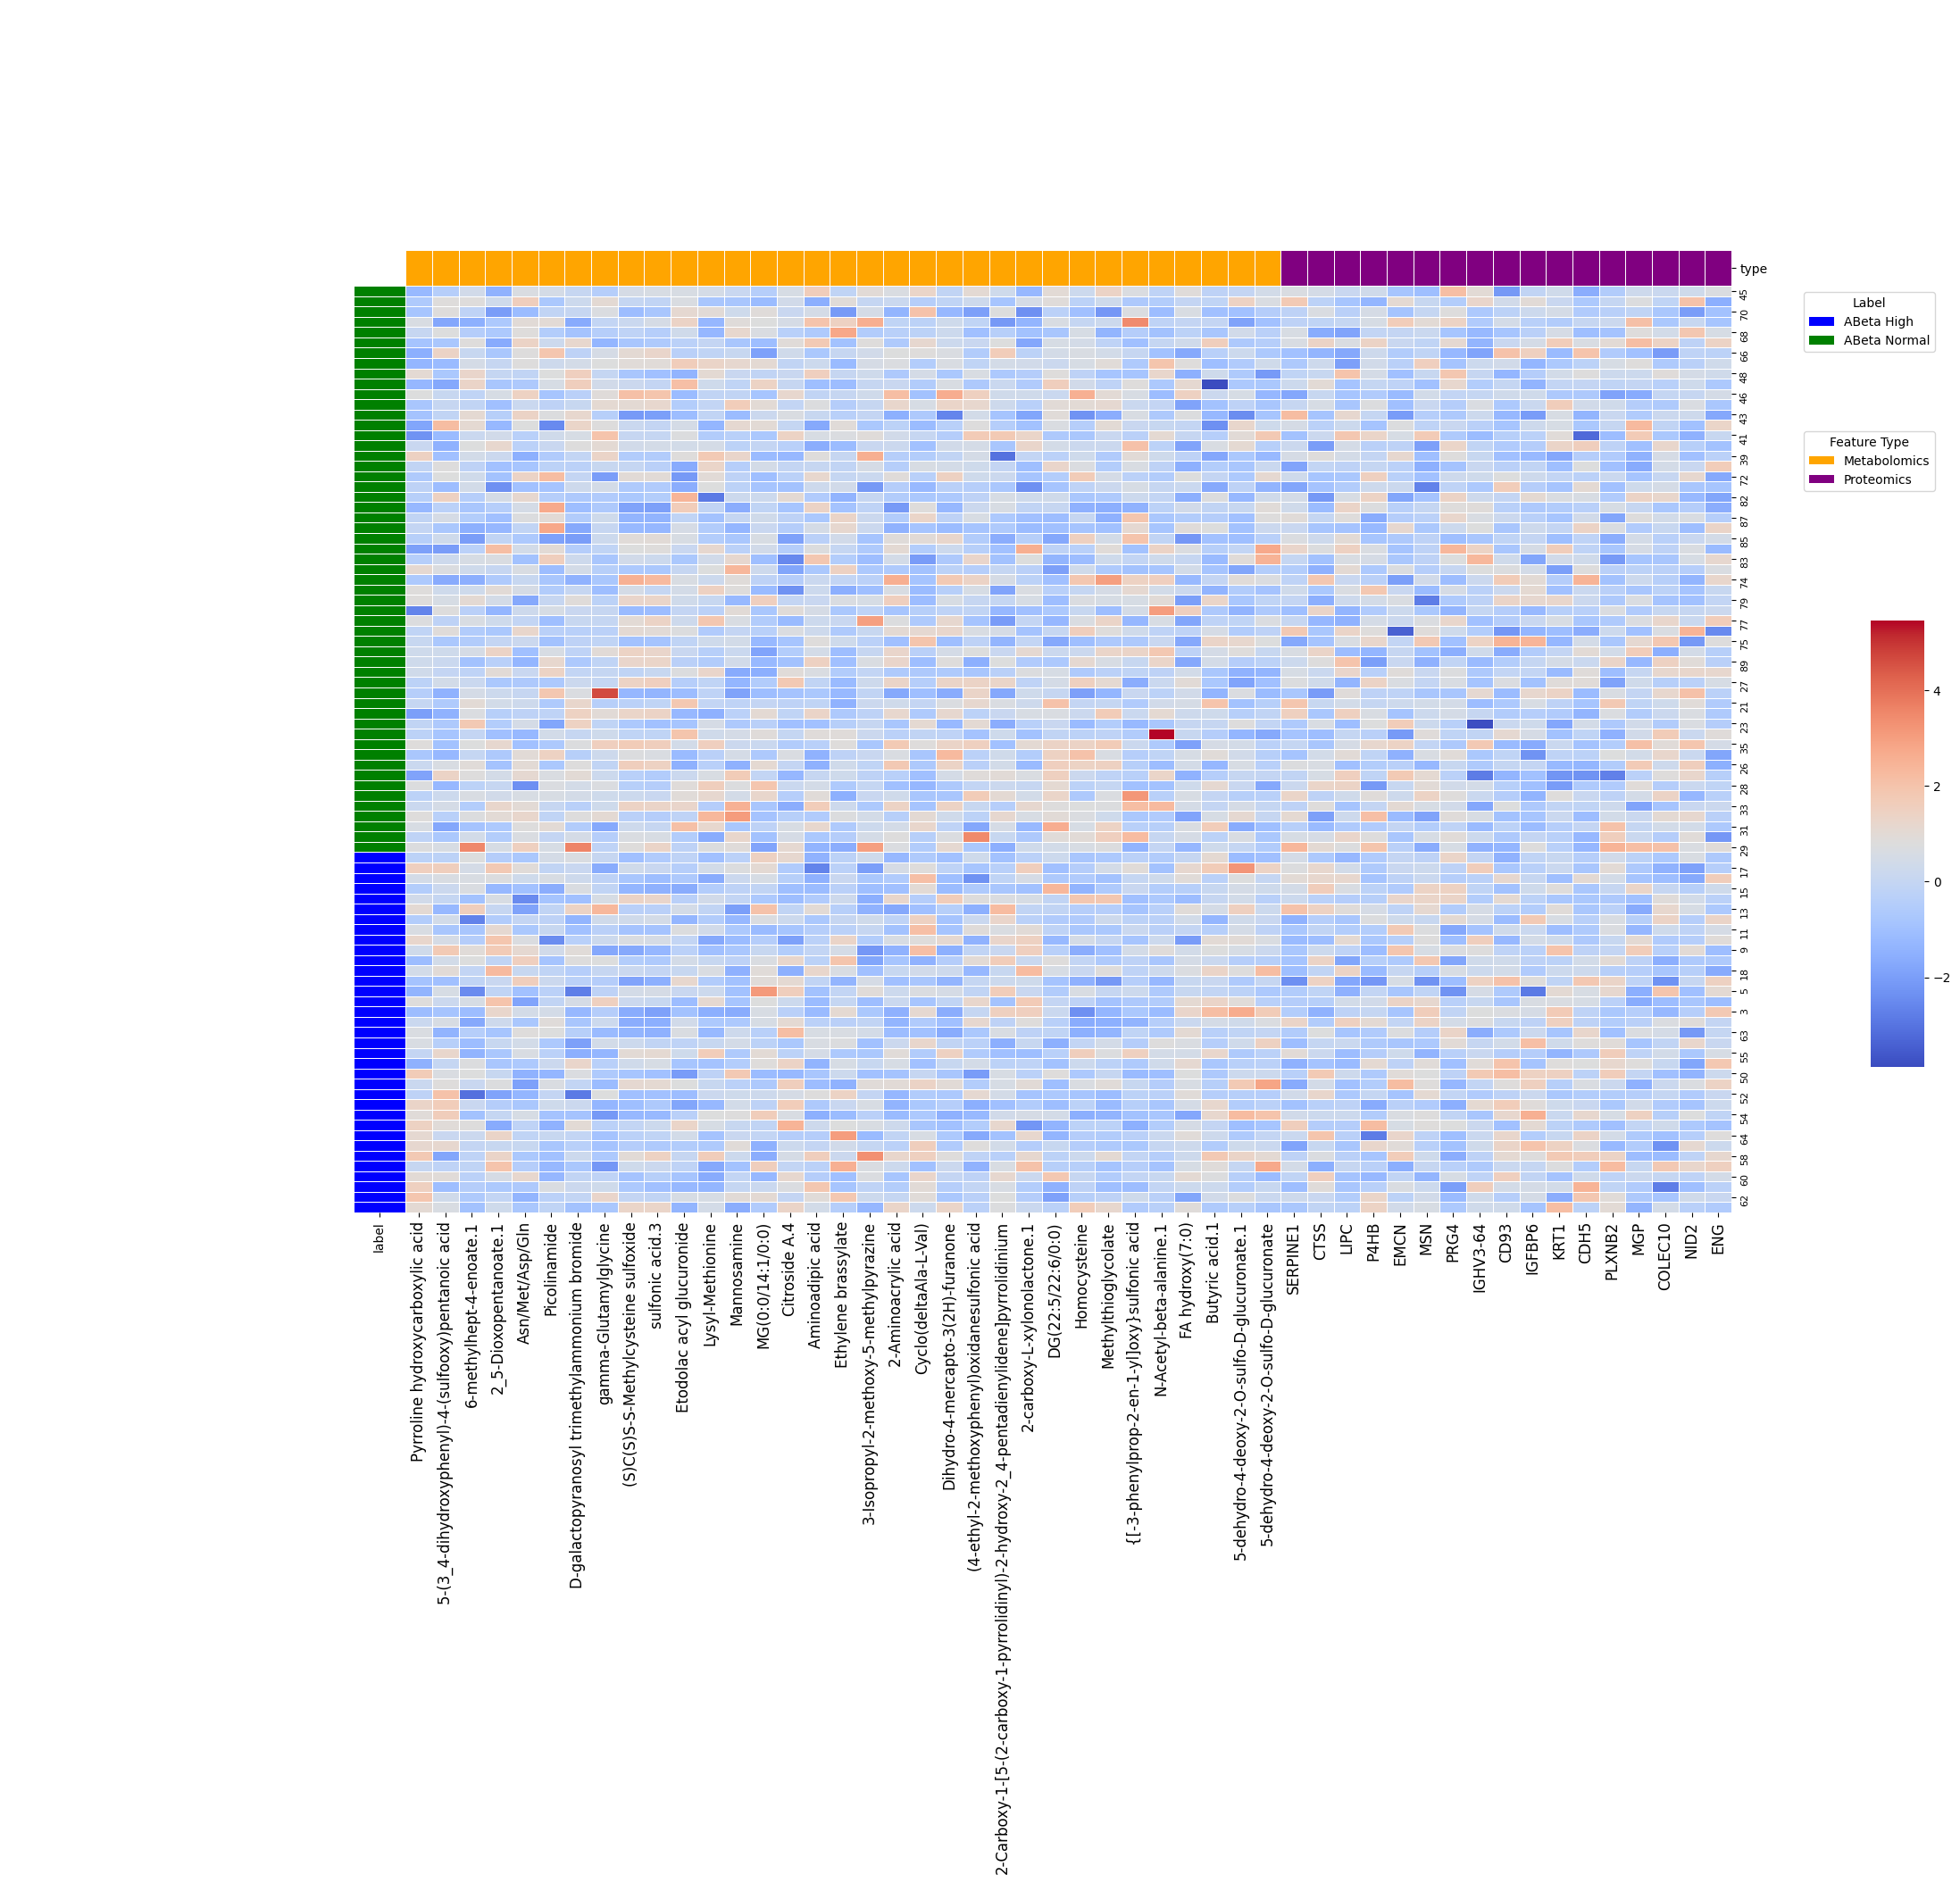

In [21]:
omics_df_vol['label'] = omics_df_vol['label'].replace({1: 'ABeta High', 0: 'ABeta Normal'})

# Selecting top 50 features and normalizing data
top_50_features = result_for_heatmap.nsmallest(50, 'pvalue')['feature'].values
heatmap_data = omics_df_vol[top_50_features]
heatmap_data = (heatmap_data - heatmap_data.mean()) / heatmap_data.std()
heatmap_data['label'] = omics_df_vol['label']

# Sorting data by labels and feature types
heatmap_data = heatmap_data.sort_values('label', ascending=False)  # Adjust based on your label order
feature_types = result_for_heatmap.set_index('feature').loc[top_50_features, 'type'].sort_values()
heatmap_data = heatmap_data[feature_types.index.tolist() + ['label']]

# Color mapping
feature_type_colors = feature_types.map({'metabolomics': 'orange', 'proteomics': 'purple'}).loc[feature_types.index]

# Plotting without automatic clustering
g = sns.clustermap(
    heatmap_data.drop(columns='label'), 
    cmap='coolwarm', 
    linewidths=0.5,
    figsize=(20, 20),
    row_colors=heatmap_data['label'].map({'ABeta High': 'blue', 'ABeta Normal': 'green'}),
    col_colors=feature_type_colors,
    cbar_pos=(1.05, 0.4, 0.03, 0.25),
    row_cluster=False,  
    col_cluster=False   
)

# Adjusting ticks and adding legends
g.ax_heatmap.tick_params(axis='x', labelsize=12)
g.ax_heatmap.tick_params(axis='y', labelsize=8)
legend1 = g.ax_heatmap.legend(handles=[Patch(facecolor='blue', label='ABeta High'), Patch(facecolor='green', label='ABeta Normal')], title='Label', loc='upper left', bbox_to_anchor=(1.05, 1))
legend2 = g.ax_heatmap.legend(handles=[Patch(facecolor='orange', label='Metabolomics'), Patch(facecolor='purple', label='Proteomics')], title='Feature Type', loc='upper left', bbox_to_anchor=(1.05, 0.85))

# Ensure legends are displayed
g.ax_heatmap.add_artist(legend1)
plt.savefig("../plots/heatmap2.png", bbox_inches='tight')
plt.show()


In [98]:
feature_type_df

,feature,type
0,A1BG,proteomics
1,A2M,proteomics
2,ABI3BP,proteomics
3,ACE,proteomics
4,ACTB,proteomics
...,...,...
1902,Disialosylgalactosylgloboside,metabolomics
1903,Demographic.Sex,demographic
1904,APOE4,demographic
1905,Age,demographic


In [99]:
omics_demo_normalise_df_no_missing

,label,APOE4,Demographic.Sex,Acetone cyanohydrin,Acetone cyanohydrin.1,Diacetyl,2-Butyne-1_4-diol,2-Butyne-1_4-diol.1,2-Aminoacrylic acid,Malonic semialdehyde,...,VCAM1,VCL,VNN1,VSIG4,VTN,VWF,YWHAZ,Collection,Demographic.Years of Education Exact,Age
0,1,1.0,0,0.206901,0.316707,0.446643,0.251892,0.354579,0.721714,0.309543,...,0.449129,0.548556,0.015636,0.623655,0.563358,0.573927,0.560821,0.6,0.545455,0.227273
1,1,0.0,0,0.300413,0.262732,0.278469,0.295970,0.245188,0.563264,0.188008,...,0.443178,0.443304,0.367330,0.625328,0.210435,0.331067,0.549499,0.0,0.545455,0.136364
2,1,1.0,0,0.559044,0.282370,0.470306,0.407029,0.252283,0.176554,0.532639,...,0.338070,0.438034,0.700905,0.366835,0.444961,0.261671,0.625963,0.0,0.090909,0.136364
3,1,1.0,0,0.479215,0.638229,0.440640,0.241416,0.130192,0.130558,0.399255,...,0.698982,0.637444,0.535274,0.750880,0.283019,0.582971,0.807185,0.0,0.090909,0.227273
4,1,0.0,0,0.423529,0.302208,0.851008,0.010261,0.187738,0.481948,0.360313,...,0.299624,0.394832,0.786952,0.316417,0.514646,0.397742,0.512103,0.0,0.545455,0.272727
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,0,0.0,1,0.690089,0.420573,0.515611,0.271983,0.110032,0.634192,0.432790,...,0.275340,0.131761,0.730523,0.841618,0.373979,0.596175,0.507556,0.7,1.000000,0.500000
86,0,1.0,1,0.336537,0.417913,0.429023,0.354724,0.167144,0.137098,0.779550,...,0.180505,0.573611,0.521113,0.117878,0.418331,0.491390,0.614897,0.1,0.454545,0.181818
87,0,1.0,1,0.182781,0.281882,0.622530,0.072207,0.167284,0.332167,0.489594,...,0.092896,0.391258,0.314103,0.475782,0.565505,0.297725,0.331308,0.4,0.181818,0.454545
88,0,1.0,1,0.314902,0.282742,0.529677,0.179087,0.229881,0.000000,0.415754,...,0.346631,0.696086,0.513452,0.362215,0.589054,0.686375,0.478666,0.2,0.545455,0.409091


In [102]:
omics_df_vol_F = omics_demo_normalise_df_no_missing[omics_demo_normalise_df_no_missing['Demographic.Sex']==0]
condition_H_F = omics_df_vol_F[omics_df_vol_F['label'] == 1].drop(columns='label')
condition_N_F = omics_df_vol_F[omics_df_vol_F['label'] == 0].drop(columns='label')
log2_fold_changes_F = []
p_values_F = []

for feature_F in condition_H_F.columns:
    mean_H_F = condition_H_F[feature_F].mean()
    mean_N_F = condition_N_F[feature_F].mean()
    log2_fc_F = np.log2(mean_H_F / mean_N_F)
    log2_fold_changes_F.append(log2_fc_F)
    
    # T-test
    _, p_value_F = ttest_ind(condition_H_F[feature_F], condition_N_F[feature_F])
    p_values_F.append(p_value_F)

# Create a DataFrame for the results
results_df_F = pd.DataFrame({
    'feature': condition_H_F.columns,
    'log2FoldChange': log2_fold_changes_F,
    'pvalue': p_values_F
})

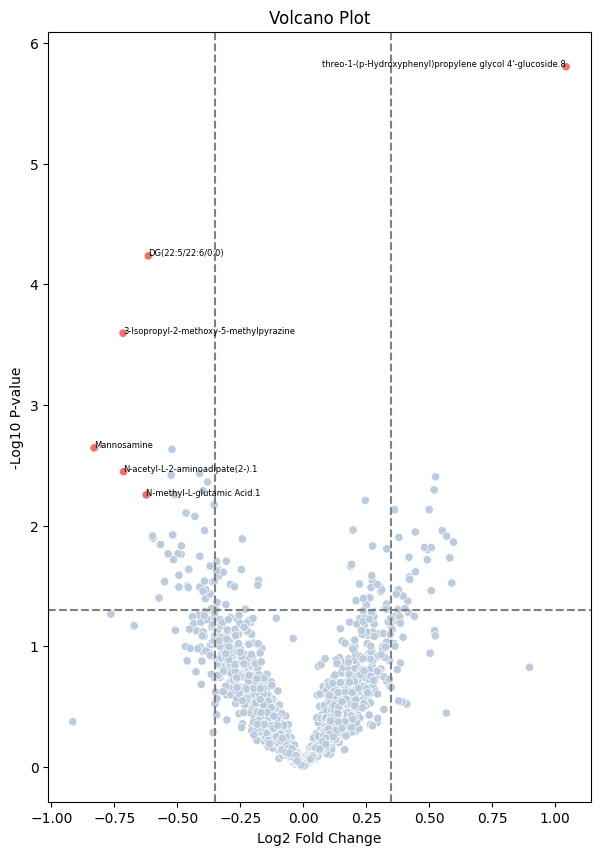

In [113]:
# Create a new column to define colors based on significance
results_df_F['color'] = '#BACCDD'  # Not significant
results_df_F.loc[(results_df_F['pvalue'] < pvalue_threshold) & (abs(results_df_F['log2FoldChange']) > 0.6), 'color'] = '#F46D6D'

# Create plot
plt.figure(figsize=(7, 10))
sns.scatterplot(x='log2FoldChange', y=-np.log10(results_df_F['pvalue']), data=results_df_F, hue='color', palette={'#BACCDD': '#BACCDD', '#F46D6D': '#F46D6D'}, legend=False)
plt.xlabel('Log2 Fold Change')
plt.ylabel('-Log10 P-value')
plt.title('Volcano Plot')

# Add threshold lines
plt.axhline(-np.log10(pvalue_threshold), color='gray', linestyle='--')
plt.axvline(log2fc_threshold, color='gray', linestyle='--')
plt.axvline(-log2fc_threshold, color='gray', linestyle='--')

# Annotate significant points
for i, row in results_df_F.iterrows():
    if row['color'] == '#F46D6D':
        ha = 'right' if row['log2FoldChange'] > log2fc_threshold else 'left'
        plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha=ha)

# for i, row in results_df.iterrows():
#     if row['color'] == '#DDBABA':
#         plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha='left')
plt.show()

In [107]:
df_sorted_F = results_df_F.sort_values(by='pvalue', ascending=True)
df_sorted_F.head(20)

,feature,log2FoldChange,pvalue,color
1047,threo-1-(p-Hydroxyphenyl)propylene glycol 4'-g...,1.043967,0.000002,#F46D6D
1326,DG(22:5/22:6/0:0),-0.615272,0.000058,#F46D6D
306,3-Isopropyl-2-methoxy-5-methylpyrazine,-0.715519,0.000254,#F46D6D
376,Mannosamine,-0.830726,0.002270,#F46D6D
461,Quinic acid,-0.520951,0.002330,#F46D6D
513,N-acetyl-L-2-aminoadipate(2-).1,-0.713425,0.003577,#F46D6D
1795,PON1,-0.411998,0.003697,#F46D6D
1755,NID2,-0.524677,0.003818,#F46D6D
1743,MRC1,0.525920,0.003946,#F46D6D
583,D-galactopyranosyl trimethylammonium bromide,-0.380007,0.004356,#F46D6D


In [108]:
result_for_heatmap_F = pd.merge(results_df_F, feature_type_df, on=['feature'],how='inner')
top_20_features_F = result_for_heatmap_F.nsmallest(20, 'pvalue')['feature'].values

In [109]:
top_20_features_F

array(["threo-1-(p-Hydroxyphenyl)propylene glycol 4'-glucoside.8",
       'DG(22:5/22:6/0:0)', '3-Isopropyl-2-methoxy-5-methylpyrazine',
       'Mannosamine', 'Quinic acid', 'N-acetyl-L-2-aminoadipate(2-).1',
       'PON1', 'NID2', 'MRC1',
       'D-galactopyranosyl trimethylammonium bromide', 'mupirocin H',
       'Mecamylamine', 'Methylthioglycolate',
       'N-methyl-L-glutamic Acid.1', 'Chrycolide',
       '6-methylhept-4-enoate.1',
       '5-dehydro-4-deoxy-2-O-sulfo-D-glucuronate', 'DPT',
       '1-deoxyxylonojirimycin', 'histidine methyl ester'], dtype=object)

In [114]:
omics_df_vol_M = omics_demo_normalise_df_no_missing[omics_demo_normalise_df_no_missing['Demographic.Sex']==1]
condition_H_M = omics_df_vol_M[omics_df_vol_M['label'] == 1].drop(columns='label')
condition_N_M = omics_df_vol_M[omics_df_vol_M['label'] == 0].drop(columns='label')
log2_fold_changes_M = []
p_values_M = []

for feature_M in condition_H_M.columns:
    mean_H_M = condition_H_M[feature_M].mean()
    mean_N_M = condition_N_M[feature_M].mean()
    log2_fc_M = np.log2(mean_H_M / mean_N_M)
    log2_fold_changes_M.append(log2_fc_M)
    
    # T-test
    _, p_value_M = ttest_ind(condition_H_M[feature_M], condition_N_M[feature_M])
    p_values_M.append(p_value_M)

# Create a DataFrame for the results
results_df_M = pd.DataFrame({
    'feature': condition_H_M.columns,
    'log2FoldChange': log2_fold_changes_M,
    'pvalue': p_values_M
})

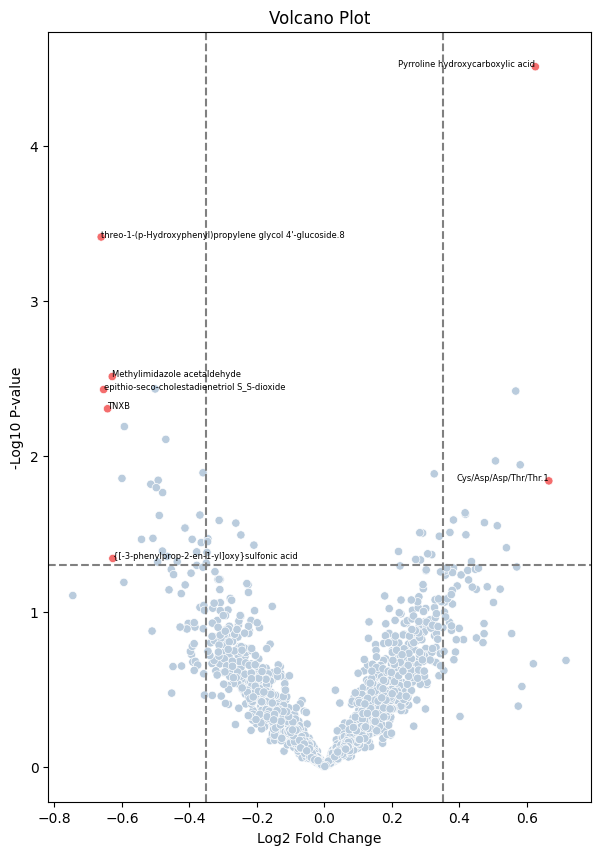

In [115]:
# Create a new column to define colors based on significance
results_df_M['color'] = '#BACCDD'  # Not significant
results_df_M.loc[(results_df_M['pvalue'] < pvalue_threshold) & (abs(results_df_M['log2FoldChange']) > 0.6), 'color'] = '#F46D6D'

# Create plot
plt.figure(figsize=(7, 10))
sns.scatterplot(x='log2FoldChange', y=-np.log10(results_df_M['pvalue']), data=results_df_M, hue='color', palette={'#BACCDD': '#BACCDD', '#F46D6D': '#F46D6D'}, legend=False)
plt.xlabel('Log2 Fold Change')
plt.ylabel('-Log10 P-value')
plt.title('Volcano Plot')

# Add threshold lines
plt.axhline(-np.log10(pvalue_threshold), color='gray', linestyle='--')
plt.axvline(log2fc_threshold, color='gray', linestyle='--')
plt.axvline(-log2fc_threshold, color='gray', linestyle='--')

# Annotate significant points
for i, row in results_df_M.iterrows():
    if row['color'] == '#F46D6D':
        ha = 'right' if row['log2FoldChange'] > log2fc_threshold else 'left'
        plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha=ha)

# for i, row in results_df.iterrows():
#     if row['color'] == '#DDBABA':
#         plt.text(row['log2FoldChange'], -np.log10(row['pvalue']), row['feature'], fontsize=6, ha='left')
plt.show()

In [116]:
df_sorted_M = results_df_M.sort_values(by='pvalue', ascending=True)
df_sorted_M.head(20)

,feature,log2FoldChange,pvalue,color
117,Pyrroline hydroxycarboxylic acid,0.624866,0.000031,#F46D6D
1047,threo-1-(p-Hydroxyphenyl)propylene glycol 4'-g...,-0.661376,0.000386,#F46D6D
93,Methylimidazole acetaldehyde,-0.628591,0.003061,#F46D6D
767,cyclopentanehexanoic acid,-0.501308,0.003680,#BACCDD
1199,epithio-seco-cholestadienetriol S_S-dioxide,-0.654128,0.003711,#F46D6D
1121,Citroside A.4,0.566640,0.003795,#BACCDD
1892,TNXB,-0.642502,0.004936,#F46D6D
1222,6beta-acetoxy-24-methylcholestan-3beta_5alpha_...,-0.592663,0.006429,#BACCDD
1239,7beta-acetoxy-gorgostan-3beta_5alpha_6beta-triol,-0.469898,0.007773,#BACCDD
1658,IGKV3D-20,0.506697,0.010701,#BACCDD


In [117]:
result_for_heatmap_M = pd.merge(results_df_M, feature_type_df, on=['feature'],how='inner')
top_20_features_M = result_for_heatmap_M.nsmallest(20, 'pvalue')['feature'].values

In [124]:
top_20_features_M

array(['Pyrroline hydroxycarboxylic acid',
       "threo-1-(p-Hydroxyphenyl)propylene glycol 4'-glucoside.8",
       'Methylimidazole acetaldehyde', 'cyclopentanehexanoic acid',
       'epithio-seco-cholestadienetriol S_S-dioxide', 'Citroside A.4',
       'TNXB',
       '6beta-acetoxy-24-methylcholestan-3beta_5alpha_22R_24-tetrol',
       '7beta-acetoxy-gorgostan-3beta_5alpha_6beta-triol', 'IGKV3D-20',
       'CTSS', 'N-hydroxyisoleucine.1',
       'N2-(gamma-Glutamyl)-4-carboxyphenylhydrazine',
       'Hydroxyoctanoic acid', '1-Aminocyclopropanecarboxylic acid',
       'Cys/Asp/Asp/Thr/Thr.1', 'Stoloniferone F', 'CACNA2D1',
       'FA (14:1)nonanoic acid',
       "6-Butyryl-5_7-dihydroxy-8-(3'_3'-dimethylallyl)-4-phenylcoumarin"],
      dtype=object)

In [122]:
combined_array = np.unique(np.concatenate((top_20_features_M, top_20_features_F)))
top_40_features = np.append(['label','Demographic.Sex'], combined_array)
heatmap_data = omics_df_vol[top_40_features]
heatmap_data

,label,Demographic.Sex,1-Aminocyclopropanecarboxylic acid,1-deoxyxylonojirimycin,3-Isopropyl-2-methoxy-5-methylpyrazine,5-dehydro-4-deoxy-2-O-sulfo-D-glucuronate,6-Butyryl-5_7-dihydroxy-8-(3'_3'-dimethylallyl)-4-phenylcoumarin,6-methylhept-4-enoate.1,6beta-acetoxy-24-methylcholestan-3beta_5alpha_22R_24-tetrol,7beta-acetoxy-gorgostan-3beta_5alpha_6beta-triol,...,PON1,Pyrroline hydroxycarboxylic acid,Quinic acid,Stoloniferone F,TNXB,cyclopentanehexanoic acid,epithio-seco-cholestadienetriol S_S-dioxide,histidine methyl ester,mupirocin H,threo-1-(p-Hydroxyphenyl)propylene glycol 4'-glucoside.8
0,ABeta High,0,0.437752,0.757621,0.158416,0.262223,0.389524,0.325964,0.224529,0.272434,...,0.599377,0.803575,0.549861,0.241394,0.400548,0.503855,0.652431,0.949142,0.751176,1.000000
1,ABeta High,0,0.573462,0.121162,0.412213,0.364445,0.721666,0.576967,0.684299,0.768899,...,0.622729,0.250707,0.015895,0.594828,0.556087,0.689981,0.555145,0.544419,0.456929,0.686964
2,ABeta High,0,0.610158,0.573063,0.453520,0.214820,0.823270,0.586503,0.615564,0.293887,...,0.473549,0.526475,0.509045,0.539503,0.295816,0.464221,0.568990,0.220145,0.308287,0.800760
3,ABeta High,0,0.321898,0.516430,0.263607,0.766635,0.650912,0.296517,0.711558,0.656339,...,0.376762,0.332750,0.220727,0.780408,0.591541,0.714378,0.523913,0.476626,0.803253,0.664012
4,ABeta High,0,0.127613,0.619359,0.198784,0.353857,0.700122,0.551261,0.389832,0.000000,...,0.323091,0.765284,0.508687,0.099156,0.296111,0.479478,0.178758,0.305017,0.487860,0.731086
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,ABeta Normal,1,0.842349,0.284666,0.238156,0.351781,0.381355,0.157083,0.681008,1.000000,...,0.475453,0.497094,0.000000,0.965053,0.347180,0.874902,0.668584,0.562041,0.544074,0.570698
86,ABeta Normal,1,0.353471,0.207623,0.431969,0.459539,0.376070,0.234310,0.710147,0.720325,...,0.539461,0.574789,0.211406,0.864106,0.595692,0.699740,0.650020,0.699273,0.496590,0.656128
87,ABeta Normal,1,0.497470,0.713130,0.431890,0.584691,0.368157,0.389508,1.000000,0.936973,...,0.517844,0.559142,0.623773,0.967650,0.300391,0.874513,0.327589,0.284435,0.444492,0.636580
88,ABeta Normal,1,0.282774,0.056513,0.364439,0.610193,0.381543,0.349662,0.740645,0.711491,...,0.562089,0.297825,0.157663,0.813189,0.432874,0.808961,0.340637,0.515549,0.258154,0.495286


In [123]:
heatmap_data.to_csv("heatmap_top40feature_gender.csv")

#### Violin plot

In [23]:
boxplot_df = omics_demo_normalise_df_no_missing.copy()
boxplot_df['label'] = boxplot_df['label'].replace({1:'High',  0:"Normal"})
boxplot_df['Demographic.Sex'] = boxplot_df['Demographic.Sex'].replace({1:"Male", 0: "Female"})
boxplot_df['APOE4'] = boxplot_df['APOE4'].replace({1:'Yes',  0:"No"})


hue_list = ['APOE4','Demographic.Sex','label']
boxplot_df[hue_list] = boxplot_df[hue_list].apply(lambda col: col.astype('category'))

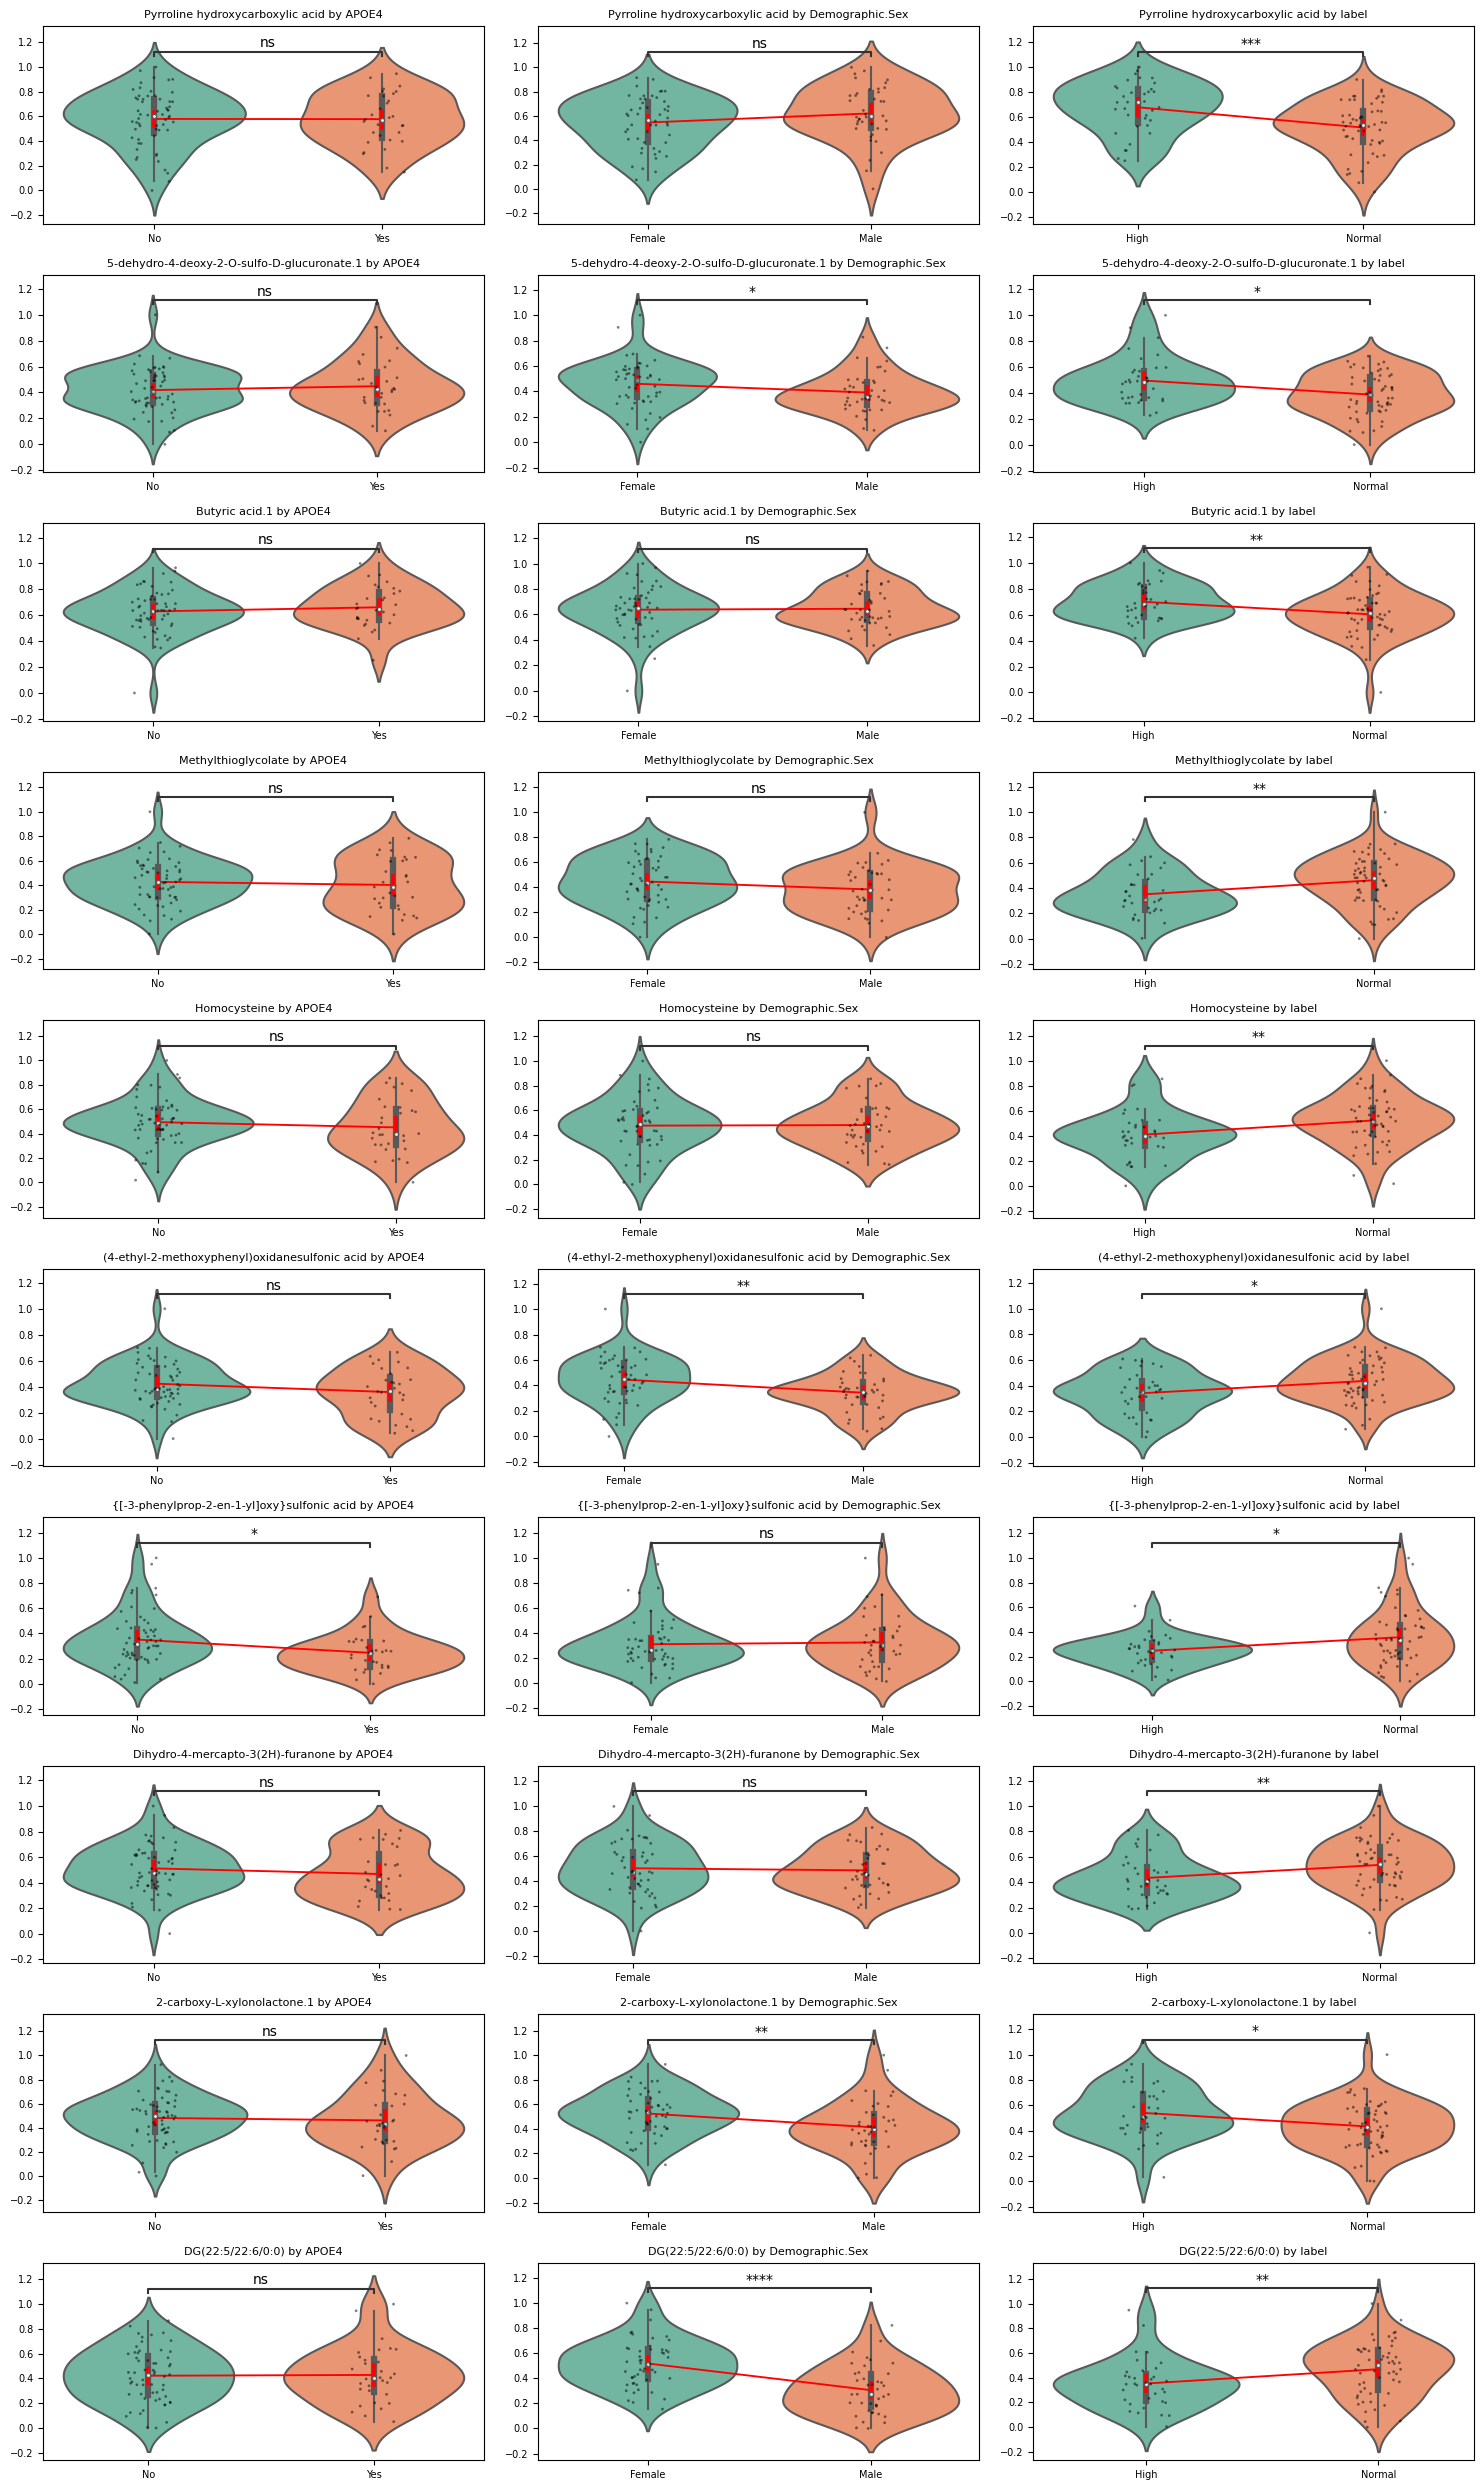

In [24]:
test_feature = ['Pyrroline hydroxycarboxylic acid', '5-dehydro-4-deoxy-2-O-sulfo-D-glucuronate.1','Butyric acid.1', 'Methylthioglycolate', 'Homocysteine', 
                '(4-ethyl-2-methoxyphenyl)oxidanesulfonic acid', '{[-3-phenylprop-2-en-1-yl]oxy}sulfonic acid', 'Dihydro-4-mercapto-3(2H)-furanone', '2-carboxy-L-xylonolactone.1',
                'DG(22:5/22:6/0:0)',]
hue_list = ['APOE4','Demographic.Sex','label']

fig, axes = plt.subplots(nrows=len(test_feature), ncols=len(hue_list), figsize=(15, 25))
for i, feature in enumerate(test_feature):
    for j, hue in enumerate(hue_list):
        ax = axes[i, j]
        sns.violinplot(x=hue, y=feature, data=boxplot_df, ax=axes[i, j], palette="Set2")
        sns.stripplot(x=hue, y=feature, data=boxplot_df, ax=axes[i, j], color='k', size=2, alpha=0.5)
        sns.pointplot(x=hue, y=feature, data=boxplot_df, ax=axes[i, j], color='red', scale=0.5, ci=95, markers='_')

        unique_values = sorted(boxplot_df[hue].unique())
        pairs = [(str(unique_values[x]), str(unique_values[y])) for x in range(len(unique_values)) for y in range(x+1, len(unique_values))]
        annotator = Annotator(ax, pairs, data=boxplot_df, x=hue, y=feature)
        annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0)
        annotator.apply_and_annotate()

        axes[i, j].set_title(f'{feature} by {hue}', fontsize=8)
        axes[i, j].set_xlabel('', fontsize=8)
        axes[i, j].set_ylabel('', fontsize=8)

        axes[i, j].tick_params(axis='x', labelsize=7)  
        axes[i, j].tick_params(axis='y', labelsize=7) 

plt.tight_layout()
plt.show()

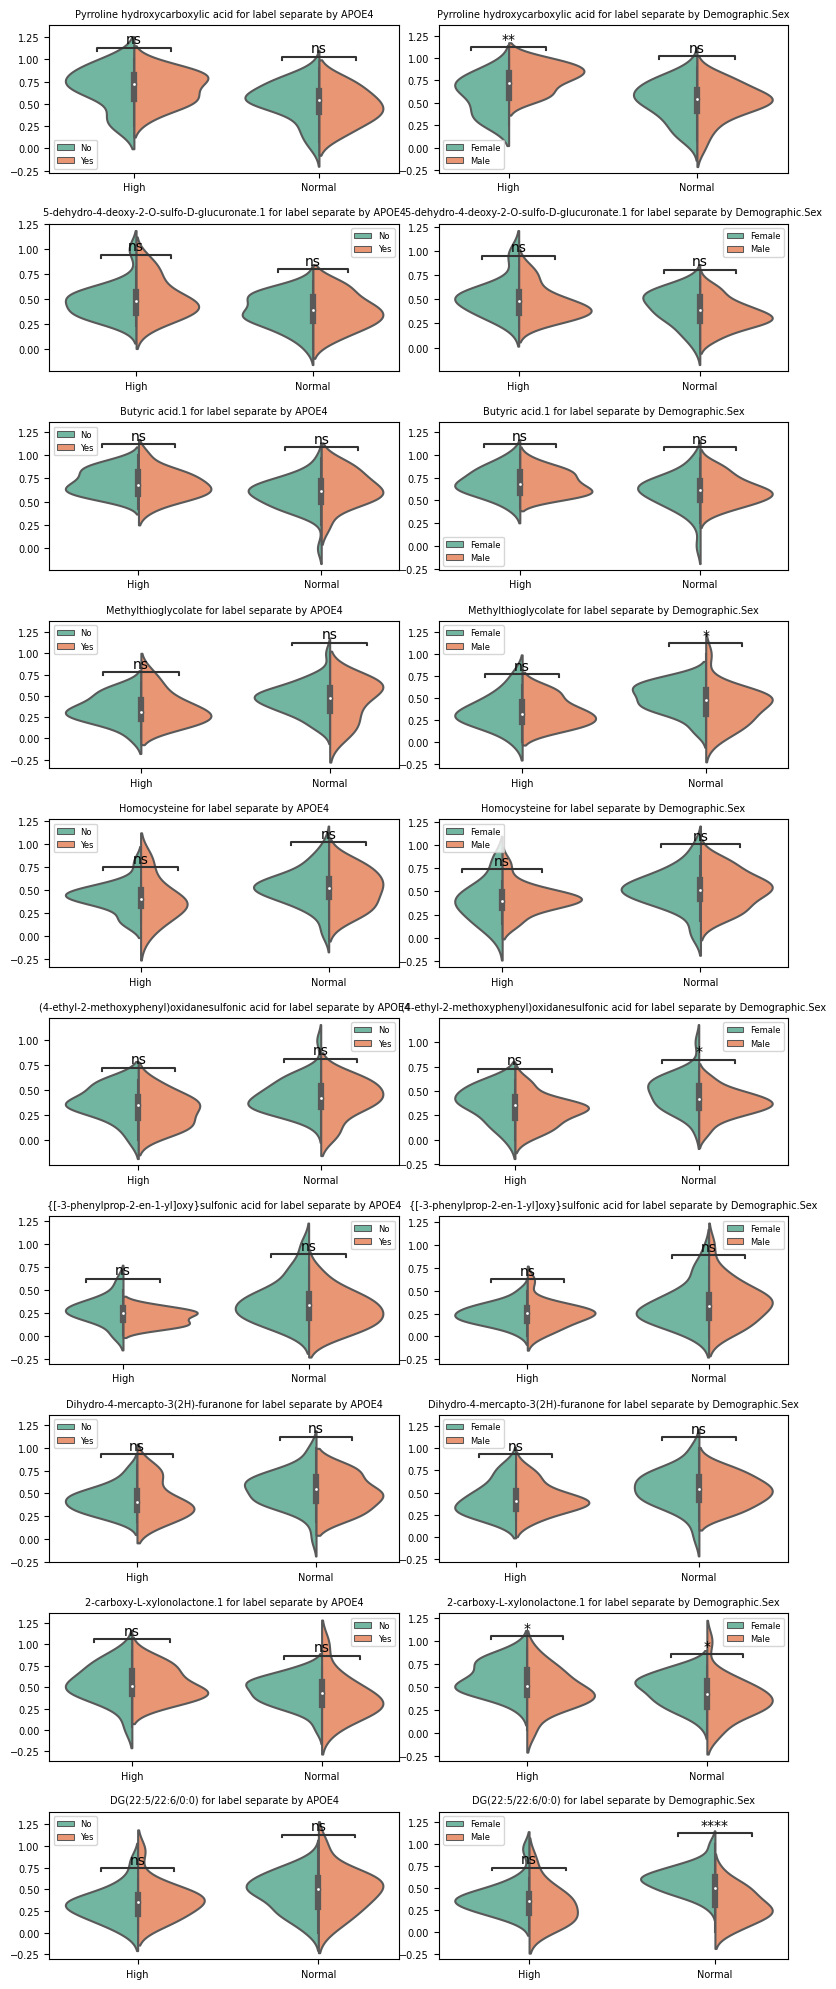

In [25]:
fig, axes = plt.subplots(nrows=len(test_feature), ncols=2, figsize=(8, 20))
for i, feature in enumerate(test_feature):
    for j, hue in enumerate(['APOE4','Demographic.Sex']):
        ax = axes[i, j]
        sns.violinplot(x='label', y=feature, data=boxplot_df, ax=axes[i, j],hue=hue, split=True, palette="Set2")

        labels = boxplot_df['label'].unique()
        hues = boxplot_df[hue].unique()
        pairs = [((label, hues[0]), (label, hues[1])) for label in labels]  # Pairing within each label

        annotator = Annotator(ax, pairs, data=boxplot_df, x='label', y=feature, hue=hue)
        annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0, line_offset=0.05) 
        annotator.apply_and_annotate()

        axes[i, j].set_title(f'{feature} for label separate by {hue}', fontsize=7)
        axes[i, j].set_xlabel('', fontsize=8)
        axes[i, j].set_ylabel('', fontsize=8)

        axes[i, j].tick_params(axis='x', labelsize=7)  
        axes[i, j].tick_params(axis='y', labelsize=7) 

        axes[i, j].legend(loc='best', fontsize=6)

plt.tight_layout()
plt.show()

In [30]:
check_centiloid = pd.read_excel('../data/raw_data/check.xlsx', sheet_name='Centiloid')
check_centiloid['Gender'] = check_centiloid['Gender'].replace({'M':"Male", 'F': "Female"})
check_centiloid

,AIBL.ID,Gender,label,Image.PET.Centiloid,at plasma
0,837,Female,H,123.1,No
1,2276,Female,H,96.4,Yes
2,2274,Female,H,38.9,Yes
3,2321,Female,H,78.1,Yes
4,2326,Female,H,30.0,Yes
...,...,...,...,...,...
85,859,Male,N,-1.7,Yes
86,2332,Male,N,12.1,Yes
87,1514,Male,N,-12.9,No
88,2077,Male,N,11.9,Yes


In [41]:
check_df = check_centiloid.copy()

check_df_F=check_df[check_df['label']=='H']
print(round(check_df_F['Image.PET.Centiloid'].mean(), 2))
print(round(check_df_F['Image.PET.Centiloid'].std(), 2))

check_df_M=check_df[check_df['label']=='N']
print(round(check_df_M['Image.PET.Centiloid'].mean(), 2))
print(round(check_df_M['Image.PET.Centiloid'].std(), 2))

64.0
35.64
2.01
6.54


In [42]:
print(min(check_df_F['Image.PET.Centiloid']))
print(max(check_df_M['Image.PET.Centiloid']))

19.2
14.4


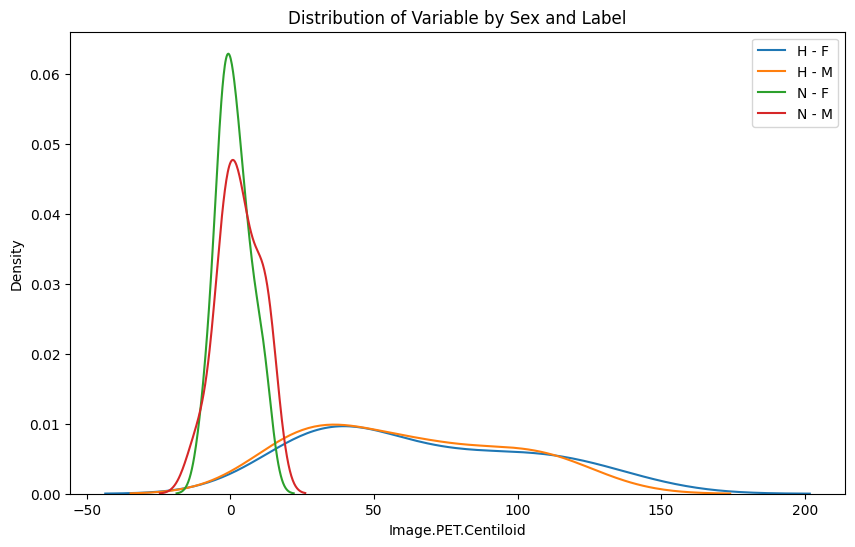

In [31]:
plt.figure(figsize=(10, 6))
labels = check_centiloid['label'].unique()
sexes = check_centiloid['Gender'].unique()

for label in labels:
    for sex in sexes:
        subset = check_centiloid[(check_centiloid['label'] == label) & (check_centiloid['Gender'] == sex)]
        sns.kdeplot(data=subset, x='Image.PET.Centiloid', label=f'{label} - {sex}', common_norm=False)

plt.title('Distribution of Variable by Sex and Label')
plt.legend()
plt.show()


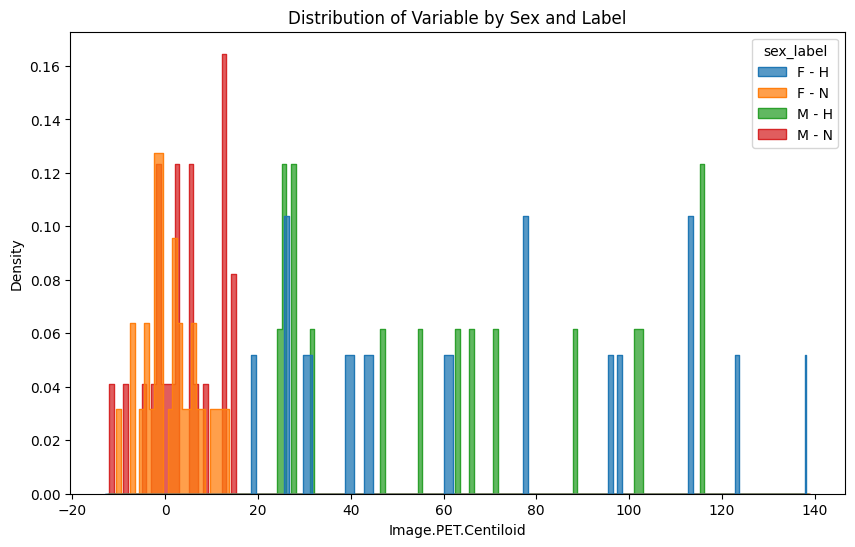

In [38]:
check_centiloid['sex_label'] = check_centiloid['Gender'] + ' - ' + check_centiloid['label']

# Plotting the distribution using histplot with smaller bins
plt.figure(figsize=(10, 6))
sns.histplot(data=check_centiloid, x='Image.PET.Centiloid', hue='sex_label', element='step', stat='density', common_norm=False, multiple='dodge', bins=150)
plt.title('Distribution of Variable by Sex and Label')
plt.show()

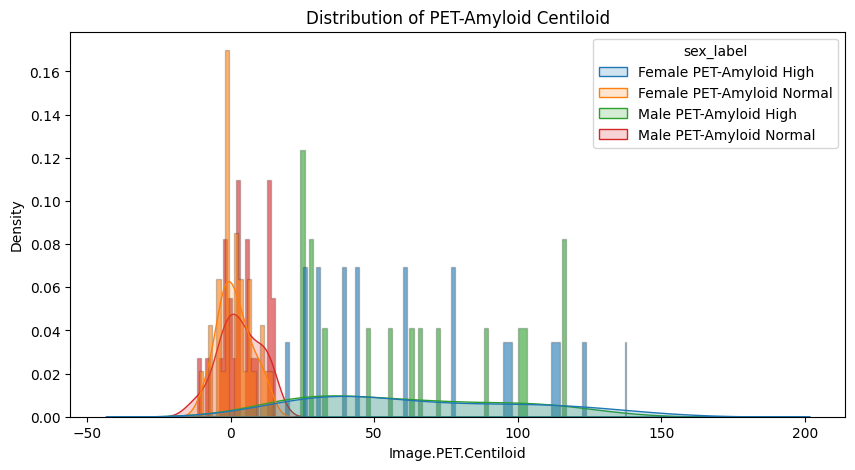

In [59]:
# Combining sex and label into one column for hue
check_centiloid['sex_label'] = check_centiloid['Gender'] + ' - ' + check_centiloid['label']
check_centiloid['sex_label'] = check_centiloid['sex_label'].replace({
    'M - H': "Male PET-Amyloid High",
    'F - H': "Female PET-Amyloid High",
    'M - N': "Male PET-Amyloid Normal", 
    'F - N': "Female PET-Amyloid Normal"
})

# Plotting the distribution using histplot with smaller bins and KDE
plt.figure(figsize=(10, 5))

# Plot histogram
sns.histplot(data=check_centiloid, x='Image.PET.Centiloid', hue='sex_label', element='step', stat='density', common_norm=False, multiple='dodge', bins=100, alpha=0.6, edgecolor=(0, 0, 0, 0.2))

# Plot KDE on top
sns.kdeplot(data=check_centiloid, x='Image.PET.Centiloid', hue='sex_label', common_norm=False, fill=True, alpha=0.2)


plt.title('Distribution of PET-Amyloid Centiloid')
plt.show()


In [34]:
centiloid_Female = check_centiloid[check_centiloid['Gender'] == 'F']
centiloid_Male = check_centiloid[check_centiloid['Gender'] == 'M']



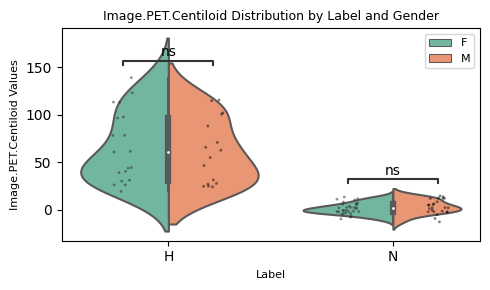

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# Assuming 'check_centiloid' is your DataFrame and contains columns 'label', 'Image.PET.Centiloid', and 'Gender'

feature_name = 'Image.PET.Centiloid'
hue_name = 'Gender'

plt.figure(figsize=(5, 3))
ax = sns.violinplot(x='label', y=feature_name, data=check_centiloid, hue=hue_name, split=True, palette="Set2")

# Stripplot without adding to the legend
strip = sns.stripplot(x='label', y=feature_name, data=check_centiloid, hue=hue_name, color='k', size=2, alpha=0.5, dodge=True)
strip.legend_.remove()  # Remove legend for stripplot

labels = check_centiloid['label'].unique()
hues = check_centiloid[hue_name].unique()
pairs = [((label, hues[0]), (label, hues[1])) for label in labels]

annotator = Annotator(ax, pairs, data=check_centiloid, x='label', y=feature_name, hue=hue_name)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0, line_offset=0.05)
annotator.apply_and_annotate()

ax.set_title(f'{feature_name} Distribution by Label and {hue_name}', fontsize=9)
ax.set_xlabel('Label', fontsize=8)
ax.set_ylabel(f'{feature_name} Values', fontsize=8)

# Adjust legend for violinplot only
handles, labels = ax.get_legend_handles_labels()
n = len(check_centiloid[hue_name].unique())  # number of hue categories
plt.legend(handles[:n], labels[:n], loc='best', fontsize=8)  # Show legend only for violinplot hues

plt.tight_layout()
plt.show()


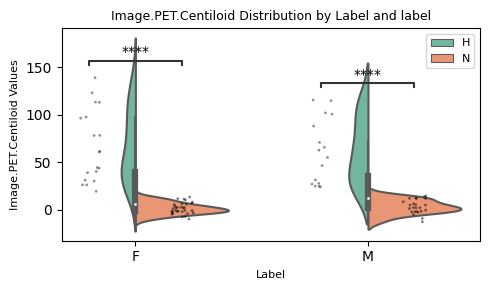

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

# Assuming 'check_centiloid' is your DataFrame and contains columns 'label', 'Image.PET.Centiloid', and 'Gender'

feature_name = 'Image.PET.Centiloid'
hue_name = 'label'

plt.figure(figsize=(5, 3))
ax = sns.violinplot(x='Gender', y=feature_name, data=check_centiloid, hue=hue_name, split=True, palette="Set2")

# Stripplot without adding to the legend
strip = sns.stripplot(x='Gender', y=feature_name, data=check_centiloid, hue=hue_name, color='k', size=2, alpha=0.5, dodge=True)
strip.legend_.remove()  # Remove legend for stripplot

labels = check_centiloid['Gender'].unique()
hues = check_centiloid[hue_name].unique()
pairs = [((label, hues[0]), (label, hues[1])) for label in labels]

annotator = Annotator(ax, pairs, data=check_centiloid, x='Gender', y=feature_name, hue=hue_name)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0, line_offset=0.05)
annotator.apply_and_annotate()

ax.set_title(f'{feature_name} Distribution by Label and {hue_name}', fontsize=9)
ax.set_xlabel('Label', fontsize=8)
ax.set_ylabel(f'{feature_name} Values', fontsize=8)

# Adjust legend for violinplot only
handles, labels = ax.get_legend_handles_labels()
n = len(check_centiloid[hue_name].unique())  # number of hue categories
plt.legend(handles[:n], labels[:n], loc='best', fontsize=8)  # Show legend only for violinplot hues

plt.tight_layout()
plt.show()

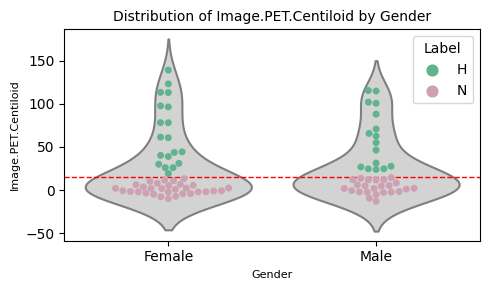

In [13]:

plt.figure(figsize=(5, 3))

sns.violinplot(
    x='Gender',
    y='Image.PET.Centiloid',
    data=check_centiloid,
    scale='width',
    linewidth=1.5,
    inner=None,  # Remove the default inner bars
    color='lightgray'
)

# Define custom colors for the dots
custom_palette = {'H': '#5fb38d', 'N': '#cda1b1'}  # Replace with your desired colors

# Overlay a swarm plot with dots colored based on the 'label' column
sns.swarmplot(
    x='Gender',
    y='Image.PET.Centiloid',
    data=check_centiloid,
    hue='label',
    dodge=False,  # Do not separate the dots horizontally
    size=5,
    palette=custom_palette  # Use the custom color palette
)

plt.axhline(y=15, color='red', linestyle='--', linewidth=1)
plt.title('Distribution of Image.PET.Centiloid by Gender', fontsize=10)
plt.xlabel('Gender', fontsize=8)
plt.ylabel('Image.PET.Centiloid', fontsize=8)

plt.legend(
    title='Label',
    loc='upper right', 
    bbox_to_anchor=(1, 1)
)

# Show the plot
plt.tight_layout()
plt.show()


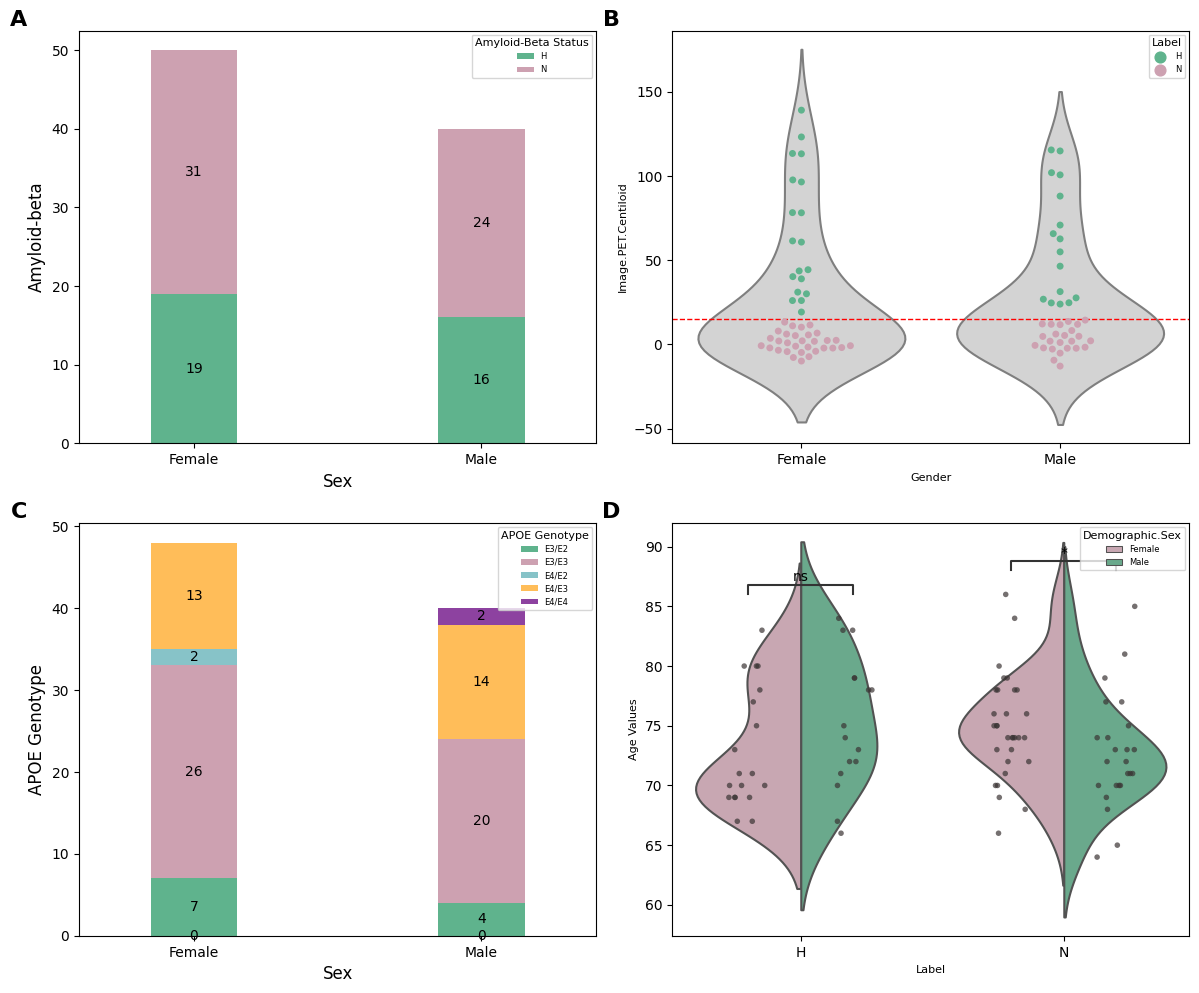

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from statannotations.Annotator import Annotator

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

### Plot (a): Stacked Bar Plot of Amyloid-beta Status by Sex ###

# Group the data and create a pivot table
pivot_df_sex = basic_statis_info_df_APOE.groupby(['Demographic.Sex', 'label']).size().unstack(fill_value=0)

# Define colors for the bars
colors = ['#5fb38d', '#cda1b1']

# Plot the stacked bar chart on the first subplot
pivot_df_sex.plot(
    kind='bar',
    stacked=True,
    ax=axes[0, 0],
    color=colors,
    width=0.3
)

# Customize the axes
axes[0, 0].set_xlabel('Sex', fontsize=12)
axes[0, 0].set_ylabel('Amyloid-beta', fontsize=12)
axes[0, 0].set_xticklabels(pivot_df_sex.index, rotation=0)

# Adjust the legend
axes[0, 0].legend(
    title='Amyloid-Beta Status',
    title_fontsize='8',
    fontsize='6',
    loc='upper right'
)

# Add value labels on the bars
for c in axes[0, 0].containers:
    axes[0, 0].bar_label(c, label_type='center')

# Add label 'a' to the top left corner
axes[0, 0].text(-0.1, 1.05, 'A', transform=axes[0, 0].transAxes,
                size=16, weight='bold', va='top', ha='right')

### Plot (b): Violin and Swarm Plot of Image.PET.Centiloid by Gender ###

# Violin plot
sns.violinplot(
    x='Gender',
    y='Image.PET.Centiloid',
    data=check_centiloid,
    scale='width',
    linewidth=1.5,
    inner=None,
    color='lightgray',
    ax=axes[0, 1]
)

# Custom colors for the swarm plot dots
custom_palette = {'H': '#5fb38d', 'N': '#cda1b1'}

# Swarm plot
sns.swarmplot(
    x='Gender',
    y='Image.PET.Centiloid',
    data=check_centiloid,
    hue='label',
    dodge=False,
    size=5,
    palette=custom_palette,
    ax=axes[0, 1]
)

# Add a horizontal line at y=15
axes[0, 1].axhline(y=15, color='red', linestyle='--', linewidth=1)

# Customize the axes
# axes[0, 1].set_title('Distribution of Image.PET.Centiloid by Gender', fontsize=10)
axes[0, 1].set_xlabel('Gender', fontsize=8)
axes[0, 1].set_ylabel('Image.PET.Centiloid', fontsize=8)

# Adjust the legend
handles, labels = axes[0, 1].get_legend_handles_labels()
axes[0, 1].legend(
    handles[:2],
    labels[:2],
    title='Label',
    title_fontsize='8',
    fontsize='6',
    loc='upper right'
)

# Add label 'b' to the top left corner
axes[0, 1].text(-0.1, 1.05, 'B', transform=axes[0, 1].transAxes,
                size=16, weight='bold', va='top', ha='right')

### Plot (c): Stacked Bar Plot of APOE Genotype by Sex ###

# Group the data and create a pivot table
pivot_df_APOE = basic_statis_info_df_APOE.groupby(['Demographic.Sex', 'Demographic.ApoE genotype']).size().unstack(fill_value=0)

# Define colors for the bars
colors = ['#5fb38d', '#cda1b1', '#87c3c8', '#ffbd59', '#8d42a0']

# Plot the stacked bar chart on the third subplot
pivot_df_APOE.plot(
    kind='bar',
    stacked=True,
    ax=axes[1, 0],
    color=colors,
    width=0.3
)

# Customize the axes
axes[1, 0].set_xlabel('Sex', fontsize=12)
axes[1, 0].set_ylabel('APOE Genotype', fontsize=12)
axes[1, 0].set_xticklabels(pivot_df_APOE.index, rotation=0)

# Adjust the legend
axes[1, 0].legend(
    title='APOE Genotype',
    title_fontsize='8',
    fontsize='6',
    loc='upper right'
)

# Add value labels on the bars
for c in axes[1, 0].containers:
    axes[1, 0].bar_label(c, label_type='center')

# Add label 'c' to the top left corner
axes[1, 0].text(-0.1, 1.05, 'C', transform=axes[1, 0].transAxes,
                size=16, weight='bold', va='top', ha='right')

### Plot (d): Violin and Strip Plot of Age by Label and Sex with Annotations ###

# Define feature and hue names
feature_name = 'Age'
hue_name = 'Demographic.Sex'

# Violin plot
violin_palette = {"Male": "#5fb38d", "Female": "#cda1b1"}
sns.violinplot(
    x='label',
    y=feature_name,
    data=basic_statis_info_df_APOE,
    hue=hue_name,
    split=True,
    palette=violin_palette,
    inner=None,
    linewidth=1.5,
    ax=axes[1, 1]
)

# Strip plot
strip_palette = {"Male": "#3a3434", "Female": "#3a3434"}
sns.stripplot(
    x='label',
    y=feature_name,
    data=basic_statis_info_df_APOE,
    hue=hue_name,
    palette=strip_palette,
    size=4,
    alpha=0.7,
    dodge=True,
    jitter=0.15,
    ax=axes[1, 1]
)

# Remove duplicate legends
handles, labels = axes[1, 1].get_legend_handles_labels()
axes[1, 1].legend(
    handles[0:2],
    labels[0:2],
    title=hue_name,
    title_fontsize='8',
    fontsize='6',
    loc='upper right'
)

# Prepare for annotations
labels_unique = basic_statis_info_df_APOE['label'].unique()
hues_unique = basic_statis_info_df_APOE[hue_name].unique()
pairs = [((label, hues_unique[0]), (label, hues_unique[1])) for label in labels_unique]

# Annotate the plot
annotator = Annotator(axes[1, 1], pairs, data=basic_statis_info_df_APOE, x='label', y=feature_name, hue=hue_name)
annotator.configure(test='Mann-Whitney', text_format='star', loc='inside', verbose=0, line_offset=0.05)
annotator.apply_and_annotate()

# Customize the axes
# axes[1, 1].set_title(f'{feature_name} Distribution by Label and {hue_name}', fontsize=9)
axes[1, 1].set_xlabel('Label', fontsize=8)
axes[1, 1].set_ylabel(f'{feature_name} Values', fontsize=8)

# Add label 'd' to the top left corner
axes[1, 1].text(-0.1, 1.05, 'D', transform=axes[1, 1].transAxes,
                size=16, weight='bold', va='top', ha='right')

# Adjust layout and display the combined plot
plt.tight_layout()
plt.savefig('combined_figure_statis.png', dpi=600, bbox_inches='tight')
plt.show()


In [77]:
plt.savefig('combined_figure_statis.png', dpi=600, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>